In [2]:
from math import floor
from sonpy import lib as sp
import pandas as pd
import re
from IPython.display import display, HTML

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import seaborn as sns
import neurokit2 as nk
import tempfile
import yaml
import os
import sys

sys.path.append(os.path.abspath(os.path.join('..','..')))
from prepro_main.spike_extraction_trim import *


In [11]:
def gastric_stethoscope_clean_plot(participant_id, df, output_yaml_path, save_dir, plots = False, figsize=(20, 6)):
    try:        
        #Load channel data
        signal_data = df['stethoscope_amplitude'].dropna().values  # Get channel data, dropping NaNs
        
        #Load sample rate from yaml file
        with open(output_yaml_path, 'r') as file:
            config = yaml.safe_load(file)
        sample_rate = config['stethoscope']['sampling_rate']
        
        
        ## FILTERING
        # Apply a notch filter at 50 Hz to remove mains interference
        nyquist = 0.5 * sample_rate
        notch_freq = 50.0
        notch_w0 = notch_freq / nyquist
        b_notch, a_notch = signal.iirnotch(notch_w0, Q=30)  # Quality factor of 30
        notched_signal = signal.filtfilt(b_notch, a_notch, signal_data)
    
        # Bandpass filter specifications (100 Hz to 500 Hz)
        low = 100
        high = 499
        b, a = signal.butter(3, [low, high], btype='bandpass', fs=sample_rate, analog=False)
        notched_butter_signal = signal.filtfilt(b, a, notched_signal)
        
        # Remove the mean from the cleaned signal
        notched_butter_demean_signal = notched_butter_signal - np.mean(notched_butter_signal)
    
        df['stethoscope_amplitude_clean'] = notched_butter_demean_signal
        cleaned_file_name = save_dir + participant_id + '_GASTRIC_stethoscope_cleaned_channel_data.tsv'
        df.to_csv(cleaned_file_name, sep = '\t', index=False)
        print('Cleaned file saved to: ' + cleaned_file_name)
        #print(df)
        
        # Task markers (these come from the 'markers' column)
        task_markers = {
            'LIVE START': 'live_start_end',
            'LIVE END': 'live_start_end',
            'REC START': 'rec_start_end',
            'REC END': 'rec_start_end',
            'START TASK': 'task_start',
            'END TASK': 'task_end',
            'QUESTION': 'question',
        }
        
        # Map markers in 'markers' column to task categories
        df['category'] = df['markers'].map(task_markers).fillna('other')
        
        # Filter out 'other' categories (for tasks)
        filtered_df = df[df['category'] != 'other']
        
        # Identify intervals for shading
        shading_intervals = {'live_start_end': [], 'rec_start_end': []}
        
        start_markers = {'live_start_end': 'LIVE START', 'rec_start_end': 'REC START'}
        end_markers = {'live_start_end': 'LIVE END', 'rec_start_end': 'REC END'}
        
        for category, start_marker in start_markers.items():
            end_marker = end_markers[category]
            
            # Find start and end times for each category
            starts = filtered_df[filtered_df['markers'] == start_marker]['time_since_start_min']
            ends = filtered_df[filtered_df['markers'] == end_marker]['time_since_start_min']
            
            # Pair start and end times for shading
            shading_intervals[category] = list(zip(starts, ends))
        
        # Marker positions for tasks and questions
        marker_positions = list(filtered_df['time_since_start_min'])
        
        # Plot
        plt_name = participant_id +'_GASTRIC_stethoscope.png'
        plt_save_path = save_dir +  '/'+ plt_name

        if plots: 
            plt.figure(figsize = figsize)
            plt.title('Original vs Cleaned Stethoscope Data')
            plt.xlabel('Time (minutes)')
            plt.ylabel('Amplitude')
            
            # Add transparent shading for intervals
            color_map = {
                'live_start_end': '#3e3e3e',
                'rec_start_end': '#a1a1a1',
                'question': 'grey',
                'task_start': 'black',  
                'task_end': 'black'   
            }
            
            for category, intervals in shading_intervals.items():
                for start, end in intervals:
                    plt.axvspan(start, end, color=color_map[category], alpha=0.2)
            
            # Add vertical lines for task markers
            for _, row in filtered_df.iterrows():
                if row['category'] == 'question':
                    plt.axvline(x=row['time_since_start_min'], color=color_map['question'], linestyle='--', alpha=0.7, linewidth=1.5)
            
            # Plot the original and cleaned signal
            plt.plot(df['time_since_start_min'].dropna().values, df['stethoscope_amplitude'].dropna().values, label='Original Signal', color='#ceebc7', alpha=0.6, lw=1.0)
            plt.plot(df['time_since_start_min'], notched_butter_demean_signal, label='Filtered Signal', color='#51C151', alpha=1.0, lw=0.2)
            plt.xlim(min(marker_positions), max(marker_positions))
            plt.ylim(min(df['stethoscope_amplitude'].dropna().values), max(df['stethoscope_amplitude'].dropna().values))
    
            #legend
            handles, labels = plt.gca().get_legend_handles_labels()
            handles.append(plt.Line2D([0], [0], color=color_map['live_start_end'], lw=2, label='LIVE START/END'))
            handles.append(plt.Line2D([0], [0], color=color_map['rec_start_end'], lw=2, label='REC START/END'))
            handles.append(plt.Line2D([0], [0], color=color_map['question'], linestyle='--', lw=2, label='QUESTION'))
            labels.append('LIVE START/END')
            labels.append('REC START/END')
            labels.append('QUESTION')
            plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1, 1))
            
            plt.tight_layout()
    
            plt_name = participant_id +'_GASTRIC_stethoscope.png'
            plt_save_path = save_dir +  '/'+ plt_name
            plt.savefig(plt_save_path, dpi=300, bbox_inches='tight')
            plt.show()

        return df, plt_save_path

    except Exception as e:
        # Handle exception and create fallback image
        print(f"An error occurred: {e}")
        df = df
        plt_name = participant_id +'_GASTRIC_stethoscope.png'

        # Create FAILED figure with green shading
        plt.figure(figsize=figsize, facecolor='white')
        plt.gca().set_facecolor('white')
        plt.text(0.5, 0.5, f"Data to produce {plt_name} not found",
                 fontsize=14, ha='center', va='center', color='#ceebc7')

        # Save the fallback image
        fallback_path = participant_id + '_GASTRICstethoscope_FAIL_image.png'
        plt_save_path = save_dir +  '/' + fallback_path
        plt.axis('off') 
        plt.savefig(plt_save_path, bbox_inches='tight', facecolor='white')
    
        return df, plt_save_path

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

def calc_euclidean(actual, predic):
    return np.sqrt(np.sum((actual - predic) ** 2))

def calc_cid(Q, C):
    CE_Q = np.sqrt(np.sum(np.diff(Q) ** 2))
    CE_C = np.sqrt(np.sum(np.diff(C) ** 2))
    
    d = np.sqrt(np.sum((Q - C) ** 2)) * (max(CE_Q, CE_C) / min(CE_Q, CE_C))
    return d    

def process_trials_and_calculate_similarity(trimmed_df, participant_id, method = 'euclidian', plots = False):
    # Initialize an empty list to collect results for all trials
    result_data = []

    trimmed_df['stethoscope_amplitude_clean'] = trimmed_df['stethoscope_amplitude_clean']
    # Task markers (these come from the 'markers' column)
    task_markers = {
        'LIVE START': 'live_start_end',
        'LIVE END': 'live_start_end',
        'REC START': 'rec_start_end',
        'REC END': 'rec_start_end',
        'START TASK': 'task_start',
        'END TASK': 'task_end',
        'QUESTION': 'question',
    }
    
    # Map markers in 'markers' column to task categories
    trimmed_df['category'] = trimmed_df['markers'].map(task_markers).fillna('other')
    
    # Filter out 'other' categories (for tasks)
    filtered_df = trimmed_df[trimmed_df['category'] != 'other']
    
    # Initialize an empty DataFrame to store trial data
    trial_df = pd.DataFrame(columns=["Trial", "Recording", "Live_Values", "Rec_Play_Values", "Similarity_Rec_Live", "Similarity_Rec_Recplay"])
    
    
    
    # Step 2: Extract RECORDING_0 first
    recording_0_idx = trimmed_df[trimmed_df['markers'] == 'RECORDING_0'].index[0]
    
    # Extract the segment from RECORDING_0 + 15000 (first 15 seconds is training) to RECORDING_0 + 30000
    rec_0_start = recording_0_idx + 14999
    rec_0_end = recording_0_idx + 29999
    rec_0_segment = trimmed_df.loc[rec_0_start:rec_0_end, 'stethoscope_amplitude_clean'].values
    
    i = 0
    # Add RECORDING_0 to trial_df
    trial_df.loc[i, "Trial"] = i
    trial_df.loc[i, "Recording"] = rec_0_segment.tolist()
    #trial_df.loc[i, "Live_Values"] = np.nan  # Will be filled later with corresponding trial live values
    #trial_df.loc[i, "Rec_Play_Values"] = np.nan  # Will be filled later with corresponding trial rec play values
    #trial_df.loc[i, "Similarity_Rec_Live"] = np.nan  # Similarity will be calculated later
    #trial_df.loc[i, "Similarity_Rec_Recplay"] = np.nan  # Similarity will be calculated later
    
    #display(HTML(trial_df.head().to_html()))
    
    
    # Step 3: Filter DataFrame from TRIAL_0-COND_Fasted onward
    trial_start_idx = trimmed_df[trimmed_df['markers'] == 'TRIAL_0-COND_Fasted'].index[0]
    filtered_df = trimmed_df.loc[trial_start_idx:]
    
    # Step 4: Find indices for LIVE START, LIVE END, REC START, and REC END
    live_start_indices = filtered_df[filtered_df['markers'] == 'LIVE START'].index
    live_end_indices = filtered_df[filtered_df['markers'] == 'LIVE END'].index
    rec_play_start_indices = filtered_df[filtered_df['markers'] == 'REC START'].index
    rec_play_end_indices = filtered_df[filtered_df['markers'] == 'REC END'].index
    recording_indices = filtered_df[filtered_df['markers'].notna() & filtered_df['markers'].str.startswith('RECORDING_')].index
    
    
    # Step 5: Loop through each trial and extract LIVE and REC_PLAY segments
    for i in range(len(live_start_indices)):  # Loop through all trials
        
        live_start = live_start_indices[i]
        live_end = live_end_indices[i]
        rec_play_start = rec_play_start_indices[i]
        rec_play_end = rec_play_end_indices[i]
        recording_idx_start = recording_indices[i] 
        
        #if verbose: 
        #    print('Trial: ', i)
            
        # Extract the recording segment (RECORDING_X)
        rec_segment_start = recording_idx_start
        rec_segment_end = rec_segment_start + 14999
        rec_segment = trimmed_df.loc[rec_segment_start:rec_segment_end, 'stethoscope_amplitude_clean'].values
        
        # Extract the live segment for the trial (LIVE START to LIVE END)
        live_segment = filtered_df.loc[live_start:live_end, 'stethoscope_amplitude_clean'].values
        
        # Extract the REC_PLAY segment for the trial (REC START to REC END)
        rec_play_segment = filtered_df.loc[rec_play_start:rec_play_end, 'stethoscope_amplitude_clean'].values
        
        # Assign live and rec_play values manually
        trial_df.loc[i, "Trial"] = i
        trial_df.loc[i, "Live_Values"] = live_segment.tolist()
        trial_df.loc[i, "Rec_Play_Values"] = rec_play_segment.tolist()
        trial_df.loc[i + 1, "Recording"] = rec_segment.tolist()
        trial_df.loc[i, "Similarity_Rec_Live"] = np.nan  # Similarity will be calculated later
        trial_df.loc[i, "Similarity_Rec_Recplay"] = np.nan  # Similarity will be calculated later
     
        
        if plots:
            plt.figure(figsize=(20, 4))
            plt.plot(rec_play_segment, label="Not Played Signal", alpha=0.5, color = '#CCCCCC')
            plt.plot(trial_df.loc[i, "Recording"], label="Recorded Signal", alpha=0.5, color = '#E5587F')
            plt.plot(trial_df.loc[i, "Live_Values"], label="Live Signal", alpha=0.5, color = '#6ED379' )
            plt.title(f"Trial {i}: Live vs Recorded")
            plt.xlabel("Sample Index")
            plt.ylabel("Amplitude")
            plt.legend()
            plt.grid(True)
            plt.show()

    # Step 6: Compute similarity measures using the calc_euclidean function
    # Iterate through each row in the DataFrame
    for i, row in trial_df.iterrows():
        live_values = row["Live_Values"] 
        rec_values = row["Recording"]
        rec_play_values = row["Rec_Play_Values"]
    
    
        # Optionally plot the results
        #plt.figure(figsize=(20, 4))
        #plt.plot(rec_play_values, label="Not Played Signal", alpha=0.7, linestyle='dashed', color = '#CCCCCC')
        #plt.plot(rec_values, label="Recorded Signal", alpha=0.7, linestyle='dashed', color = '#E5587F')
        #plt.plot(live_values, label="Live Signal", alpha=0.7, color = '#6ED379' )
        #plt.title(f"Trial {i + 1}: Live vs Recorded")
        #plt.xlabel("Sample Index")
        #plt.ylabel("Amplitude")
        #plt.legend()
        #plt.grid(True)
        #plt.show()
        
        # Check if the values are lists or arrays, and handle cases where they are floats
        if isinstance(live_values, (list, np.ndarray)) and isinstance(rec_values, (list, np.ndarray)) and isinstance(rec_play_values, (list, np.ndarray)):
            # Find the shortest length
            min_length = min(len(live_values), len(rec_values), len(rec_play_values))
    
            # Trim the arrays to the shortest length
            live_values = live_values[:min_length]
            rec_values = rec_values[:min_length]
            rec_play_values = rec_play_values[:min_length]
            time_indices = np.arange(min_length)  # Create an array of time indices
    
            # Calculate similarity between Live and Recording for each trial (Pearson correlation)
            if len(live_values) > 1 and len(rec_values) > 1:
                sim_rec_live = pearsonr(live_values, rec_values)[0]
            else:
                sim_rec_live = np.nan
            
            # Calculate similarity between Rec_Play and Recording for each trial (Pearson correlation)
            if len(rec_play_values) > 1 and len(rec_values) > 1:
                sim_rec_recplay = pearsonr(rec_play_values, rec_values)[0]
            else:
                sim_rec_recplay = np.nan
    
            # Calculate correlation along the time dimension
            
            
            if len(live_values) > 1:
                actual = np.array(live_values)
                predic = np.array(rec_values)
                if method == 'euclician':
                    sim_time_rec_live = calc_euclidean(actual, predic)
                else: 
                    sim_time_rec_live = calc_cid(actual, predic)
            else:
                sim_time_rec_live = np.nan
    
            if len(rec_play_values) > 1:
                actual = np.array(live_values)
                predic = np.array(rec_play_values)
                if method == 'euclician':
                    sim_time_rec_recplay = calc_euclidean(actual, predic)
                else:
                    sim_time_rec_recplay = calc_cid(actual, predic)
            else:
                sim_time_rec_recplay = np.nan
    
            if len(live_values) > 1:
                actual = np.array(live_values)
                predic = np.array(live_values)
                if method == 'euclician':
                    sim_time_live_live = calc_euclidean(actual, predic)
                else:
                    sim_time_live_live = calc_cid(actual, predic)
            else:
                sim_time_live_live = np.nan
    
    
            if len(live_values) > 1:
                actual = np.array(live_values)
                control_zeros = np.zeros(len(live_values))  # Control vector of zeros
                if method == 'euclician':
                    sim_time_live_control_zeros = calc_euclidean(actual, control_zeros)  # Compare actual vs control
                else:
                    sim_time_live_control_zeros = calc_cid(actual, control_zeros)  # Compare actual vs control
    
                # Generate noise based on the distribution of live_values (same length)
                mean = np.mean(live_values)  # Calculate the mean of live_values
                std = np.std(live_values)    # Calculate the standard deviation of live_values
                # Generate control_noise with a normal distribution based on live_values
                control_noise = np.random.normal(loc=mean, scale=std, size=len(live_values))
                if method == 'euclician':
                    sim_time_live_control_noise = calc_euclidean(actual, control_noise)  # Compare actual vs control
                else:
                    sim_time_live_control_noise = calc_cid(actual, control_noise)  # Compare actual vs control
            else:
                sim_time_live_control = np.nan  # Assign NaN when live_values is too short
                sim_time_live_control_noise = np.nan
        else:
            # If values are floats or not valid lists/arrays, skip the similarity calculation
            sim_rec_live = np.nan
            sim_rec_recplay = np.nan
            sim_time_rec_live = np.nan
            sim_time_rec_recplay = np.nan
    
        # Update the row with calculated similarities
        trial_df.loc[i, "Similarity_Rec_Live"] = sim_rec_live
        trial_df.loc[i, "Similarity_Rec_Recplay"] = sim_rec_recplay
        trial_df.loc[i, "SimilarityTime_Rec_Live"] = sim_time_rec_live
        trial_df.loc[i, "SimilarityTime_Rec_Recplay"] = sim_time_rec_recplay
    
        trial_df.loc[i, "SimilarityTime_Live_Live"] = sim_time_live_live
        trial_df.loc[i, "SimilarityTime_Live_Control_Zeros"] = sim_time_live_control_zeros
        trial_df.loc[i, "SimilarityTime_Live_Control_Noise"] = sim_time_live_control_noise
    
        # Append the results to the list
        if i == 30:
            continue
        else:
            result_data.append({
                "participant_id": participant_id,
                "Trial": i,
                "SimilarityTime_Live_Live": sim_time_live_live,
                "SimilarityTime_Live_Control_Zeros": sim_time_live_control_zeros,
                "SimilarityTime_Live_Control_Noise": sim_time_live_control_noise,
                "SimilarityTime_Rec_Live": sim_time_rec_live,
                "SimilarityTime_Rec_Recplay": sim_time_rec_recplay
            })

    trial_df = trial_df.drop(trial_df.index[-1]) #remove the last row = (index 31 - only recording not real trial)
    
    if plots:        
        # Create a DataFrame with the relevant columns for easier plotting
        plot_df = trial_df[['SimilarityTime_Live_Live', 'SimilarityTime_Live_Control_Zeros', 'SimilarityTime_Live_Control_Noise', 'SimilarityTime_Rec_Live', 'SimilarityTime_Rec_Recplay']]
        
        plt.figure(figsize=(12, 6))
        sns.boxplot(data=plot_df, orient="h", linewidth=1.5, color='black', width=0.5, fill=None)
        y_jitter = np.random.uniform(-0.1, 0.1, size=len(trial_df))  # Small jitter for spacing
        plt.scatter(trial_df['SimilarityTime_Live_Live'], 0 + y_jitter, 
                    color='#6ED379', alpha=0.7, label='Trial Points (Time_Live_Live)', zorder=3)
        
        plt.scatter(trial_df['SimilarityTime_Live_Control_Zeros'], 1 + y_jitter, 
                    color='#AED3B2', alpha=0.7, label='Trial Points (Time_Live_Control)', zorder=3)
        
        
        plt.scatter(trial_df['SimilarityTime_Live_Control_Noise'], 2 + y_jitter, 
                    color='#AED3B2', alpha=0.7, label='Trial Points (Time_Live_Control)', zorder=3)
        
        
        plt.scatter(trial_df['SimilarityTime_Rec_Live'], 3 + y_jitter, 
                    color='#E5587F', alpha=0.7, label='Trial Points (Time_Rec_Live)', zorder=3)
        
        plt.scatter(trial_df['SimilarityTime_Rec_Recplay'], 4 + y_jitter, 
                    color='#CCCCCC', alpha=0.7, label='Trial Points (Time_Rec_Recplay)', zorder=3)
        plt.xlabel('Similarity', fontsize=12)
        plt.yticks([0, 1, 2, 3, 4], ['SimilarityTime_Live_Live', 'SimilarityTime_Live_Control_Zeros','SimilarityTime_Live_Control_Noise', 'SimilarityTime_Rec_Live', 'SimilarityTime_Rec_Recplay'], fontsize=12)
        plt.title('Similarity Comparison: Live vs Recorded (Including Time Dimension)', fontsize=14)
    
        plt.legend()
        plt.grid(True, axis='x', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()
    
    
        plt.figure(figsize=(20, 4))
        plt.plot(trial_df['SimilarityTime_Rec_Live'], label="SimilarityTime_Rec_Live", alpha=0.7, linestyle='dashed', color = '#CCCCCC')
        plt.plot(trial_df['SimilarityTime_Rec_Recplay'], label="SimilarityTime_Rec_Recplay", alpha=0.7, linestyle='dashed', color = '#E5587F')
        plt.title(f"Live vs Recorded")
        plt.xlabel("Trial")
        plt.ylabel("Amplitude")
        plt.legend()
        plt.grid(True)
        plt.show()

    

    # Convert the result data to a DataFrame
    return pd.DataFrame(result_data)

C:\Users\hsavage\AppData\Local\Temp\ipykernel_13232\1625680984.py:28: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


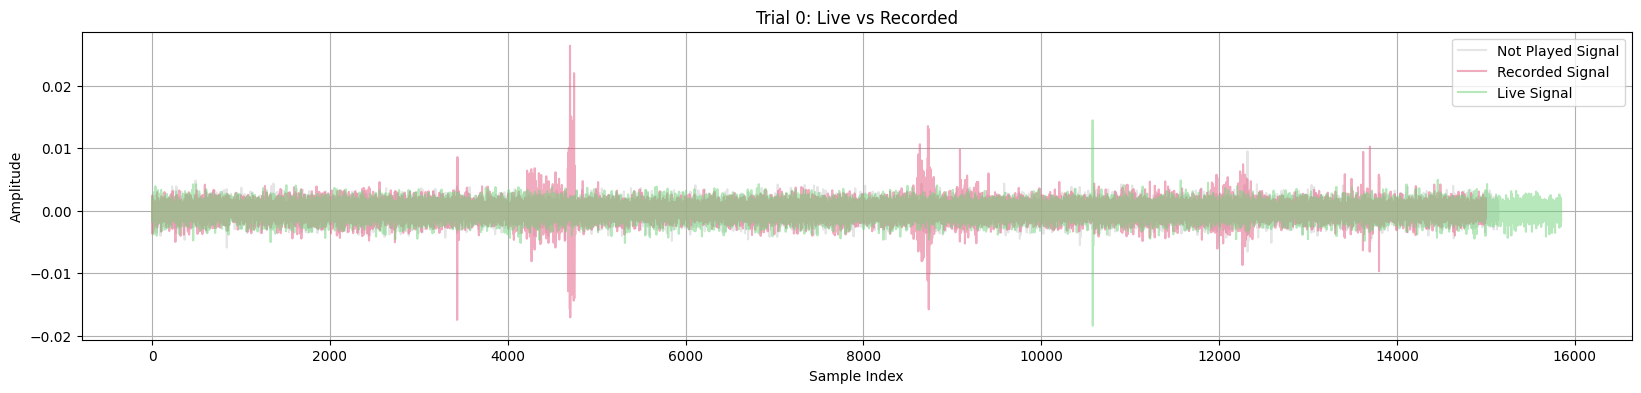

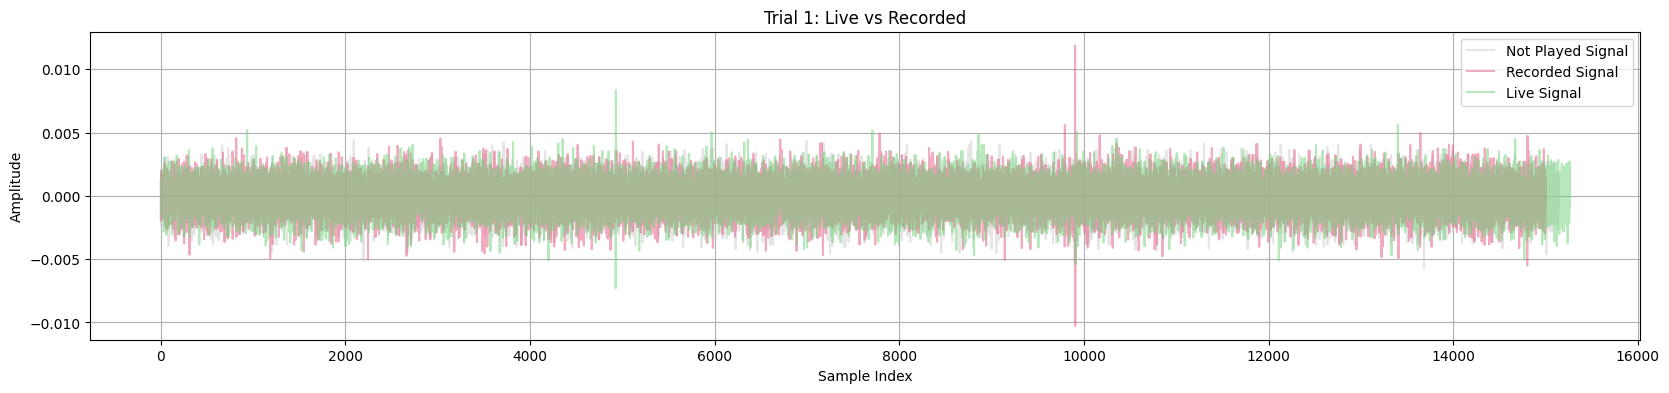

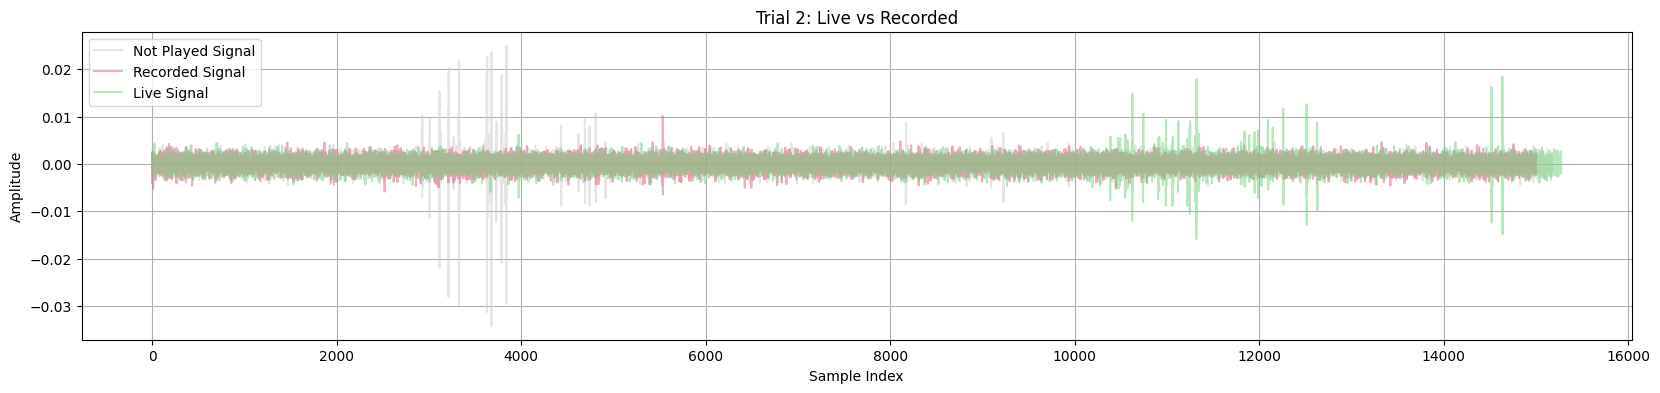

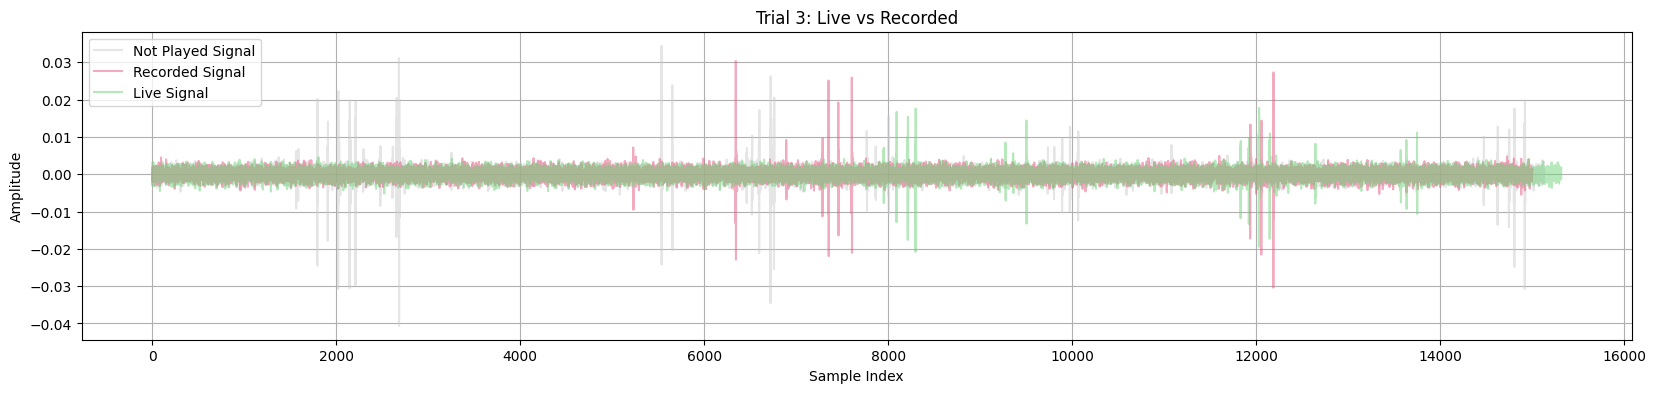

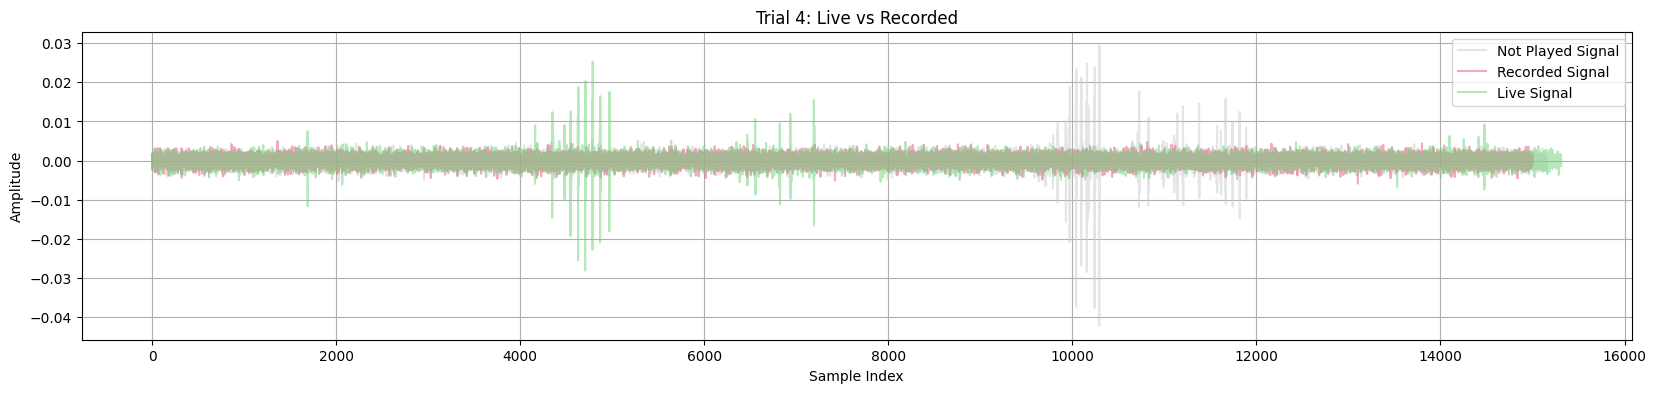

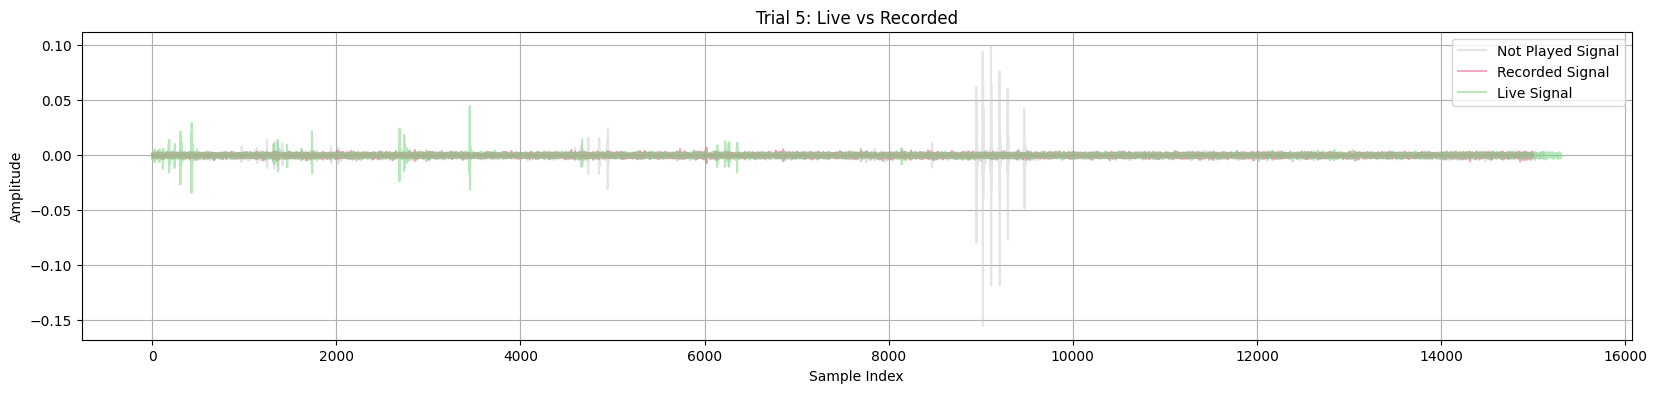

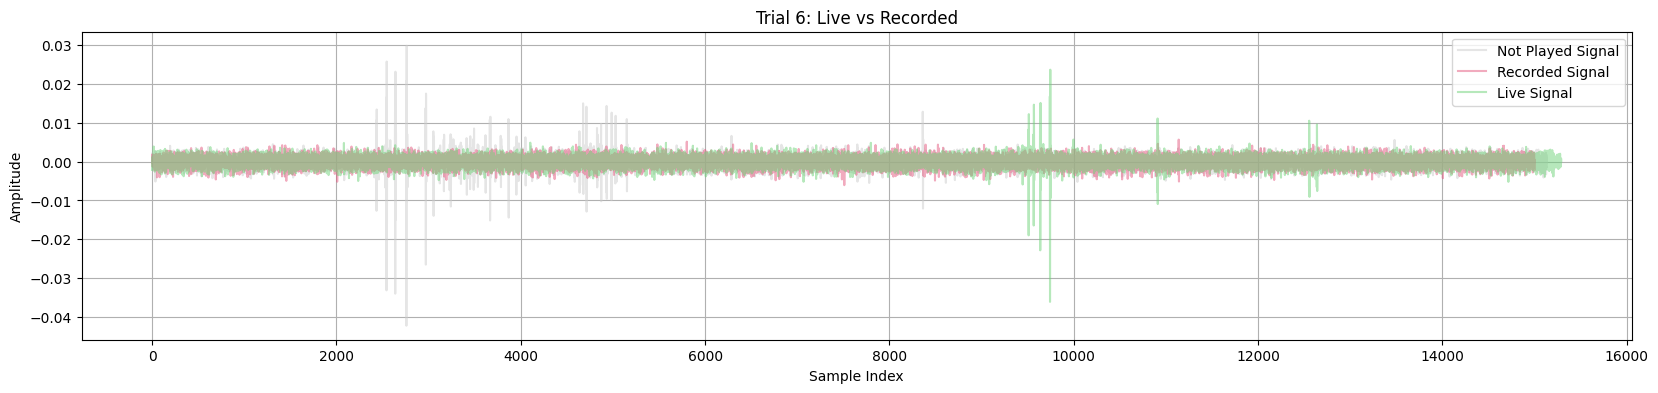

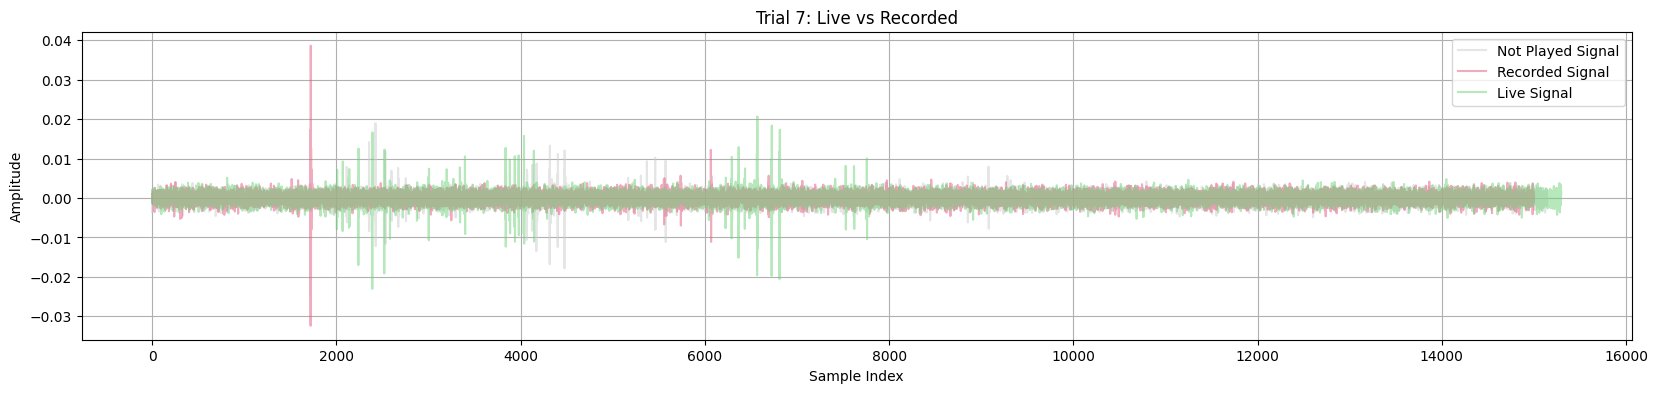

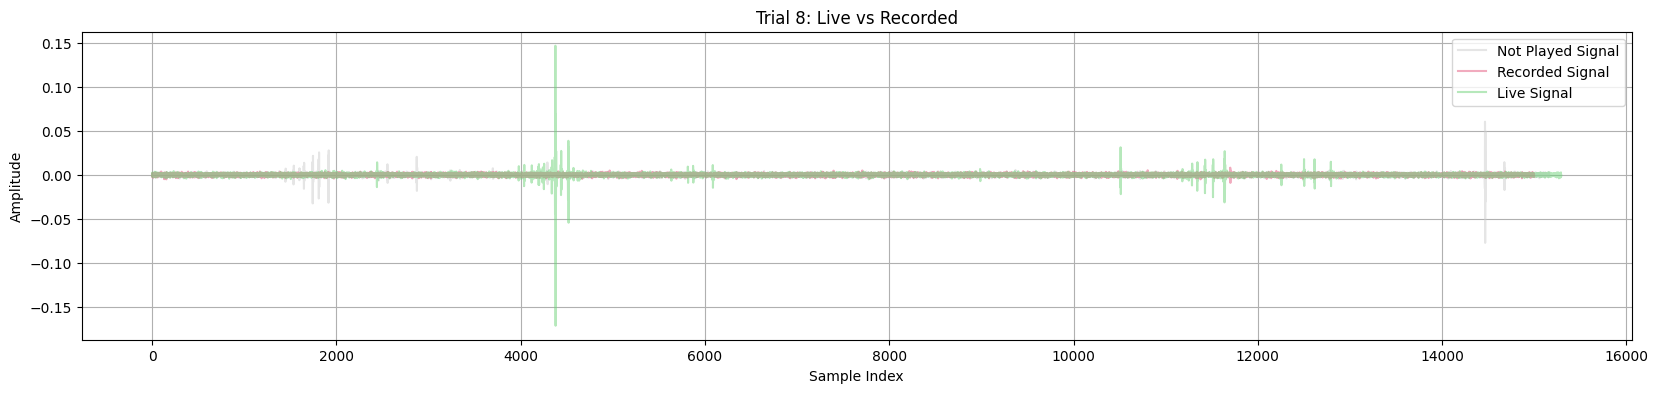

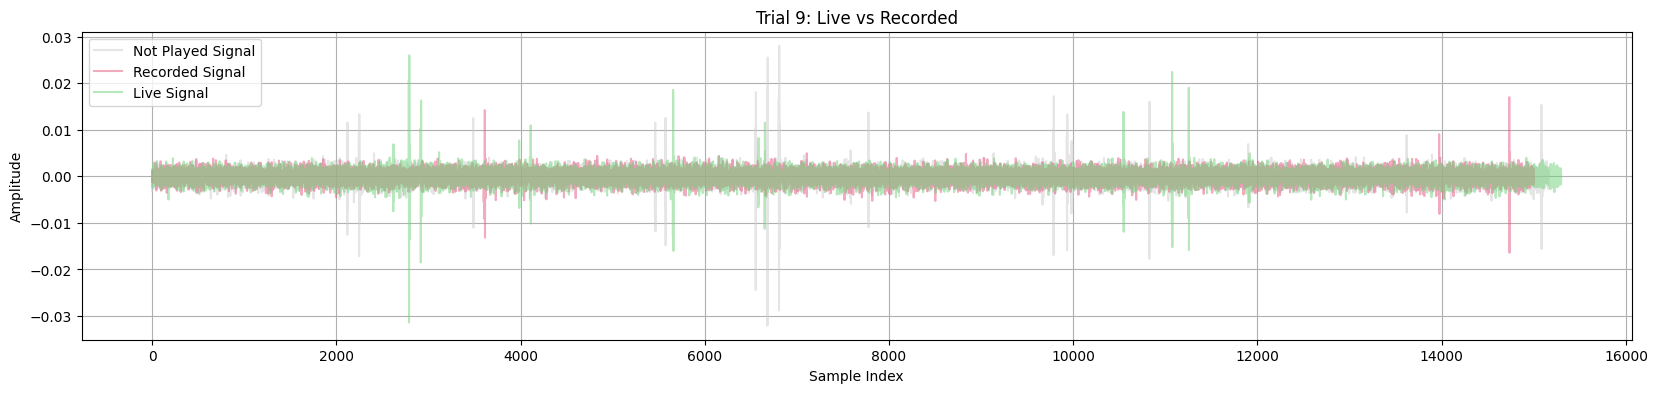

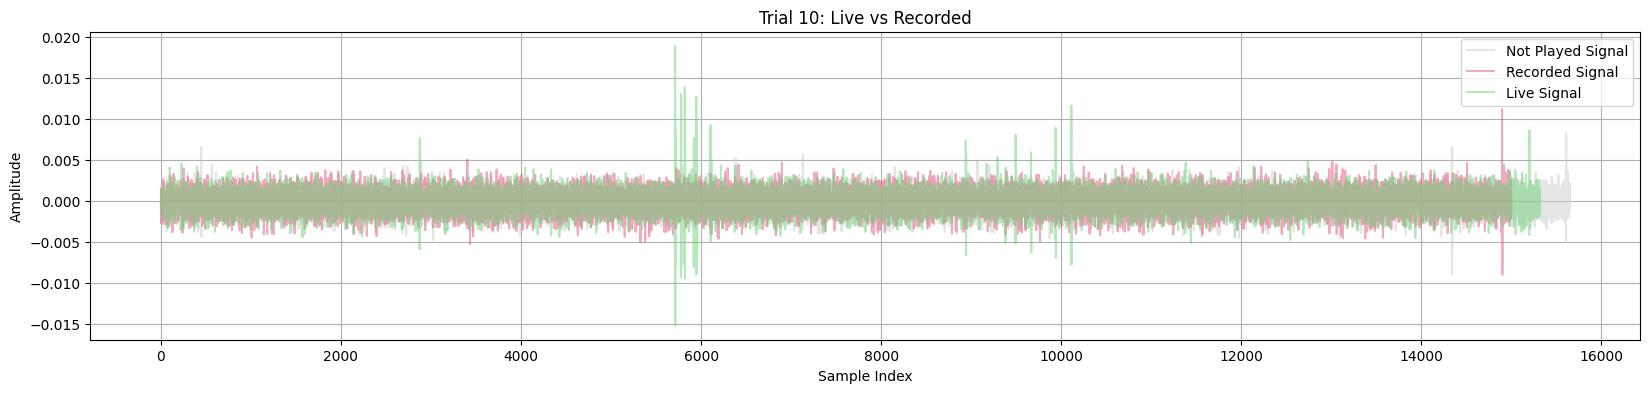

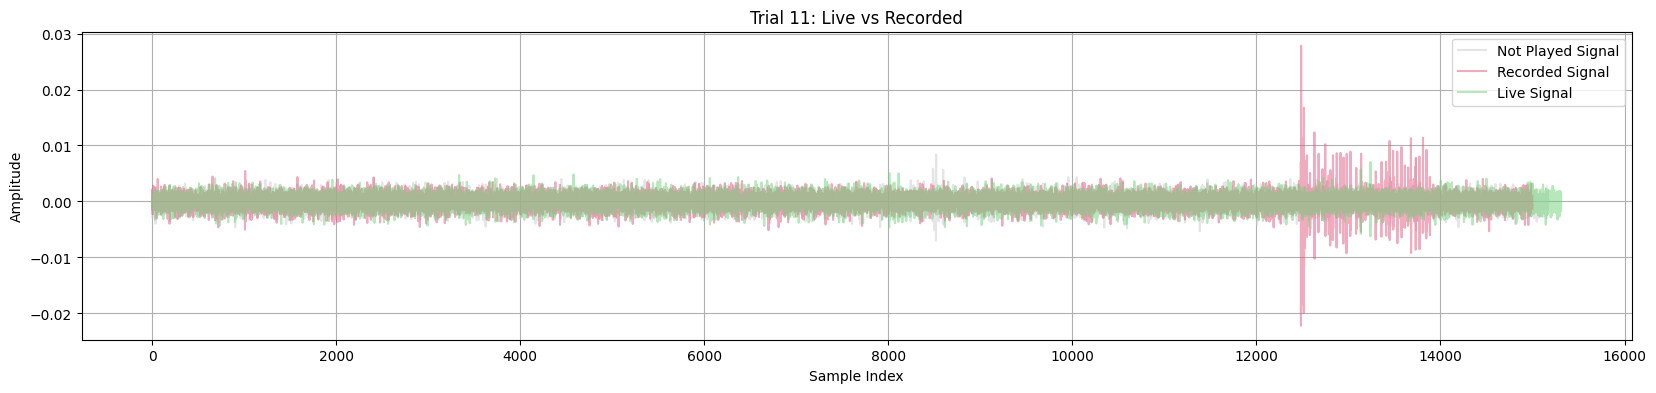

KeyboardInterrupt: 

In [ ]:
task = 'GASTRIC'
folder_path = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio/extracted'  # Edit folder path
save_dir = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio/'

# Main processing loop for participants
group_df = pd.DataFrame(columns=["participant_id", "Trial", 
                                 "SimilarityTime_Live_Live", "SimilarityTime_Live_Control_Zeros", 
                                 "SimilarityTime_Live_Control_Noise", "SimilarityTime_Rec_Live", 
                                 "SimilarityTime_Rec_Recplay"])
file_names = []
cleaned_file_already_saved = True

for root, dirs, files in os.walk(folder_path):
    for file_name in files:
        #print(root)
        #print(file_name)
        #print(dirs)
        if file_name.endswith("_GASTRIC_trimmed_channel_data.tsv"):

            file_path = os.path.join(root, file_name)
            #print(file_path)

            # Extract the participant ID from the filename (assuming the format "sub-XXX_gastric_stethascope.tsv")
            participant_id = file_name.split('_')[0]  # Get the part before the first underscore (sub-XXX)
            
            if cleaned_file_already_saved:
                file_path = save_dir + f"{participant_id}_" + task + '_stethoscope_cleaned_channel_data.tsv'
                clean_trimmed_df = pd.read_csv(file_path, sep = '\t') 
            
            else:
                file_names.append(participant_id)
                trimmed_df = pd.read_csv(file_path, sep = '\t')
                print(trimmed_df)
                yaml_path = folder_path + f"/{participant_id}_" + task + '_spike_channel_info.yaml'
                clean_trimmed_df, plt_save_path = gastric_stethoscope_clean_plot(participant_id, trimmed_df, yaml_path, save_dir)
            
            
            participant_group_df = process_trials_and_calculate_similarity(clean_trimmed_df, participant_id, method = 'cid', plots = True)
            # Concatenate the results for the participant to the group_df
            group_df = pd.concat([group_df, participant_group_df], ignore_index=True)

print(group_df)
group_df.to_csv('Trial_by_trial_similarity.csv', index = False)            

In [ ]:
import pandas as pd

def calculate_time_intervals(clean_trimmed_df):
    # Find relevant indices
    recording_9_idx = clean_trimmed_df[clean_trimmed_df['markers'] == 'RECORDING_9'].index[0]
    question_9_idx = clean_trimmed_df[(clean_trimmed_df.index > recording_9_idx) & (clean_trimmed_df['markers'] == 'QUESTION')].index[0]
    print(question_9_idx)
    trial_9_idx = clean_trimmed_df[clean_trimmed_df['markers'] == 'TRIAL_9-COND_Post_Drink_1'].index[0]
    print(trial_9_idx)

    recording_19_idx = clean_trimmed_df[clean_trimmed_df['markers'] == 'RECORDING_19'].index[0]
    question_19_idx = clean_trimmed_df[(clean_trimmed_df.index > recording_19_idx) & (clean_trimmed_df['markers'] == 'QUESTION')].index[0]
    trial_19_idx = clean_trimmed_df[clean_trimmed_df['markers'] == 'TRIAL_19-COND_Post_Drink_2'].index[0]
    
    # Calculate time differences
    fasted_sparking_sec = (trial_9_idx - question_9_idx) / 100
    fasted_sparking_min = fasted_sparking_sec / 60
    
    sparking_protein_sec = (trial_19_idx - question_19_idx) / 100
    sparking_protein_min = sparking_protein_sec / 60
    
    # Create results DataFrame
    results_df = pd.DataFrame({
        'fasted_sparking_sec': [fasted_sparking_sec],
        'fasted_sparking_min': [fasted_sparking_min],
        'sparking_protein_sec': [sparking_protein_sec],
        'sparking_protein_min': [sparking_protein_min]
    })
    
    return results_df

task = 'GASTRIC'
folder_path = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio'  # Edit folder path
save_dir = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio/'

# Main processing loop for participants
group_df = pd.DataFrame(columns=["Participant_id", "Trial", 
                                 "SimilarityTime_Live_Live", "SimilarityTime_Live_Control_Zeros", 
                                 "SimilarityTime_Live_Control_Noise", "SimilarityTime_Rec_Live", 
                                 "SimilarityTime_Rec_Recplay"])

cleaned_file_already_saved = True

for root, dirs, files in os.walk(folder_path):
    for file_name in files:
        #print(root)
        #print(file_name)
        #print(dirs)
        if file_name.endswith("_GASTRIC_trimmed_channel_data.tsv"):

            file_path = os.path.join(root, file_name)
            #print(file_path)

            # Extract the participant ID from the filename (assuming the format "sub-XXX_gastric_stethascope.tsv")
            participant_id = file_name.split('_')[0]  # Get the part before the first underscore (sub-XXX)
            
            if cleaned_file_already_saved:
                file_path = save_dir + f"{participant_id}_" + task + '_stethoscope_cleaned_channel_data.tsv'
                clean_trimmed_df = pd.read_csv(file_path, sep = '\t') 
            
            else:
                file_names.append(participant_id)
                trimmed_df = pd.read_csv(file_path, sep = '\t')
                #print(trimmed_df)
                yaml_path = save_dir + f"{participant_id}_" + task + '_spike_channel_info.yaml'
                clean_trimmed_df, plt_save_path = gastric_stethoscope_clean_plot(participant_id, trimmed_df, yaml_path, save_dir)
            
            #print(clean_trimmed_df['markers'].dropna())
            
            participant_group_df = calculate_time_intervals(clean_trimmed_df)
            # Concatenate the results for the participant to the group_df
            group_df = pd.concat([group_df, participant_group_df], ignore_index=True)

print(group_df)
#group_df.to_csv('Duration_of_drinking.csv')            

In [28]:
# Similarity Calculation (Analysis B)
similarity_results = []

# Split trials into sets of 0-9, 10-19, 20-29
trial_sets = [(0, 9), (10, 19), (20, 29)]

for start, end in trial_sets:
    subset = group_df[(group_df['Trial'] >= start) & (group_df['Trial'] <= end)]
    
    # Calculate averages for each participant
    for participant in subset['participant_id'].unique():
        participant_data = subset[subset['participant_id'] == participant]
        
        # Calculate the mean for each similarity column
        avg_live_live = participant_data['SimilarityTime_Live_Live'].mean()
        avg_control_zeros = participant_data['SimilarityTime_Live_Control_Zeros'].mean()
        avg_control_noise = participant_data['SimilarityTime_Live_Control_Noise'].mean()
        avg_rec_live = participant_data['SimilarityTime_Rec_Live'].mean()
        avg_rec_recplay = participant_data['SimilarityTime_Rec_Recplay'].mean()
        
        # Determine the trial range and condition
        trial_range = f'{start}-{end}'
        if trial_range == '0-9':
            condition = 'fasted'
        elif trial_range == '10-19':
            condition = 'sparkling_water'
        elif trial_range == '20-29':
            condition = 'protein_shake'
        else:
            condition = 'unknown'
        
        # Append the result for this participant and trial range
        similarity_results.append({
            'Participant': participant,
            'Trial_Range': trial_range,
            'Condition': condition,
            'Avg_Similarity_Live_Live': avg_live_live,
            'Avg_Similarity_Control_Zeros': avg_control_zeros,
            'Avg_Similarity_Control_Noise': avg_control_noise,
            'Avg_Similarity_Rec_Live': avg_rec_live,
            'Avg_Similarity_Rec_Recplay': avg_rec_recplay
        })

# Convert similarity results to DataFrame
similarity_df = pd.DataFrame(similarity_results)

# Display the resulting DataFrame
display(HTML(similarity_df.to_html()))

# Show summary statistics
print(similarity_df.describe())

similarity_df.to_csv('Average_similarity_per_condition.csv')

,Participant,Trial_Range,Condition,Avg_Similarity_Live_Live,Avg_Similarity_Control_Zeros,Avg_Similarity_Control_Noise,Avg_Similarity_Rec_Live,Avg_Similarity_Rec_Recplay
0,sub-004,0-9,fasted,0.0,inf,0.300783,0.321885,0.395877
1,sub-006,0-9,fasted,0.0,inf,0.392452,1.198188,2.327290
2,sub-007,0-9,fasted,0.0,inf,0.207527,0.208674,0.233931
3,sub-008,0-9,fasted,0.0,inf,0.304197,0.255227,0.253779
4,sub-011,0-9,fasted,0.0,inf,0.270247,0.293972,0.308959
5,sub-024,0-9,fasted,0.0,inf,0.247114,0.297330,0.293338
6,sub-028,0-9,fasted,0.0,inf,0.205790,0.219790,0.235424
7,sub-030,0-9,fasted,0.0,inf,0.220415,0.199636,0.195421
8,sub-036,0-9,fasted,0.0,inf,0.293029,0.384072,0.242100
9,sub-037,0-9,fasted,0.0,inf,0.300691,0.436850,0.397156


       Avg_Similarity_Live_Live  Avg_Similarity_Control_Zeros  \
count                     135.0                         135.0   
mean                        0.0                           inf   
std                         0.0                           NaN   
min                         0.0                           inf   
25%                         0.0                           NaN   
50%                         0.0                           NaN   
75%                         0.0                           NaN   
max                         0.0                           inf   

       Avg_Similarity_Control_Noise  Avg_Similarity_Rec_Live  \
count                    135.000000               135.000000   
mean                       0.265589                 0.345130   
std                        0.095197                 0.314155   
min                        0.138610                 0.140154   
25%                        0.209520                 0.220093   
50%                        0.2

C:\Users\hsavage\Documents\GitHub\Em-Body_toolkit-1\myenv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\hsavage\Documents\GitHub\Em-Body_toolkit-1\myenv\lib\site-packages\numpy\lib\function_base.py:4527: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


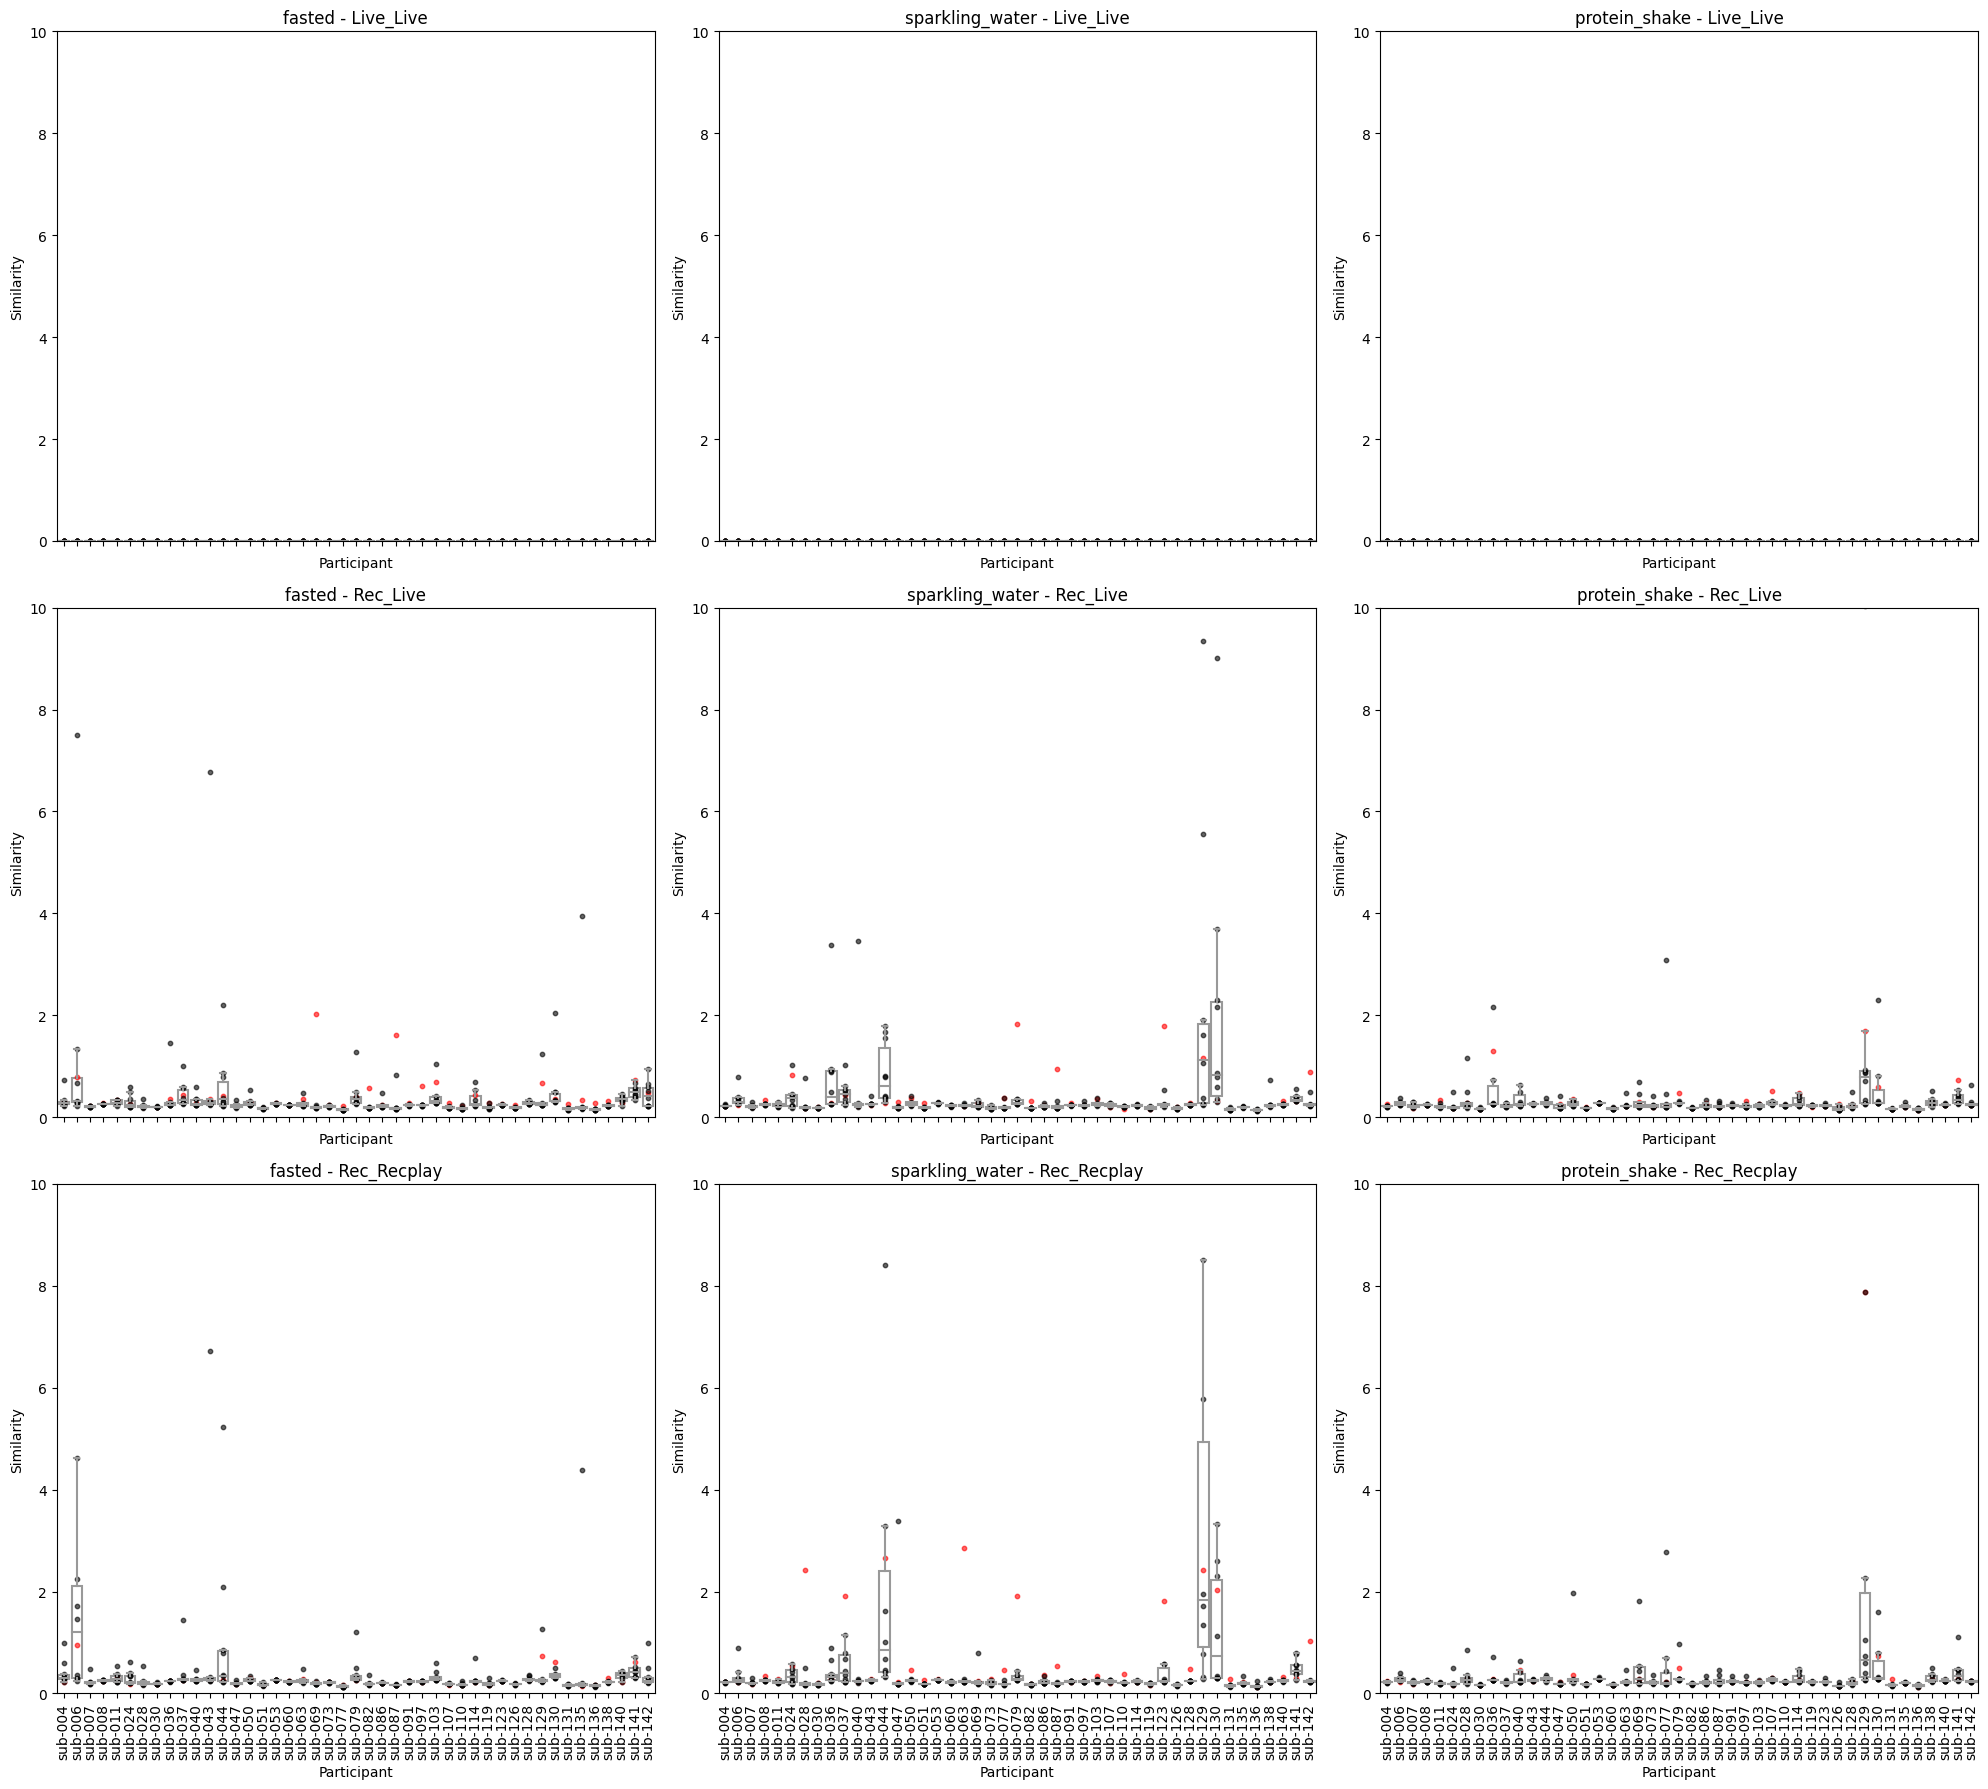

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

group_df = pd.read_csv('Trial_by_trial_similarity.csv')

# Assuming group_df is your dataframe
# First, define the trial ranges and condition logic
trial_sets = [(0, 9), (10, 19), (20, 29)]
def assign_condition(trial):
    if trial >= 0 and trial <= 9:
        return 'fasted'
    elif trial >= 10 and trial <= 19:
        return 'sparkling_water'
    elif trial >= 20 and trial <= 29:
        return 'protein_shake'
    else:
        return 'unknown'

# Apply the condition assignment
group_df['Condition'] = group_df['Trial'].apply(assign_condition)

# List of similarity columns to plot
similarity_columns = ['SimilarityTime_Live_Live', 'SimilarityTime_Rec_Live', 'SimilarityTime_Rec_Recplay']

# Set up the 3x3 subplots (3 rows, 3 columns for each condition)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 18))

# Get global min and max for consistent y-axis scaling across all boxplots
y_min = group_df[similarity_columns].min().min()  # Minimum value across all similarity columns
y_max = group_df[similarity_columns].max().max()  # Maximum value across all similarity columns

# Loop through each similarity column and each condition to create boxplots and scatter
for i, col in enumerate(similarity_columns):
    for j, condition in enumerate(['fasted', 'sparkling_water', 'protein_shake']):
        ax = axes[i, j]  # Select the appropriate subplot

        # Filter the DataFrame by the current condition
        condition_data = group_df[group_df['Condition'] == condition]

        # Create a boxplot for the current similarity column for each participant
        sns.boxplot(x='participant_id', y=col, data=condition_data, ax=ax, fliersize=0, color='white')

        # Filter data for trials 0, 10, or 21
        red_trials = condition_data[condition_data['Trial'].isin([0, 10, 21])]

        # Overlay scatter points for red trials (trial 0, 10, or 21)
        ax.scatter(red_trials['participant_id'], red_trials[col], 
                   color='red', alpha=0.6, label='Trial 0, 10, or 21', s=10)

        # Overlay scatter points for all other trials (excluding trial 0, 10, or 21)
        other_trials = condition_data[~condition_data['Trial'].isin([0, 10, 21])]
        ax.scatter(other_trials['participant_id'], other_trials[col], 
                   color='black', alpha=0.6, label=f'{condition} trials', s=10)

        # Set titles, labels, and consistent y-axis range
        ax.set_title(f'{condition} - {col.split("_")[-2]}_{col.split("_")[-1]}')
        ax.set_xlabel('Participant')
        ax.set_ylabel('Similarity')
        ax.set_ylim(y_min - 0.1, y_max + 0.1)  # Ensure consistent y-axis scaling across all subplots
        ax.set_ylim(0, 10)  # Set the y-axis range from 0 to 2.5
        ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

        # Remove x-tick labels for all rows except the last (bottom row)
        if i != 2:
            ax.set_xticklabels([])

# Adjust the layout for better readability
plt.tight_layout()

# Display the plots
plt.show()


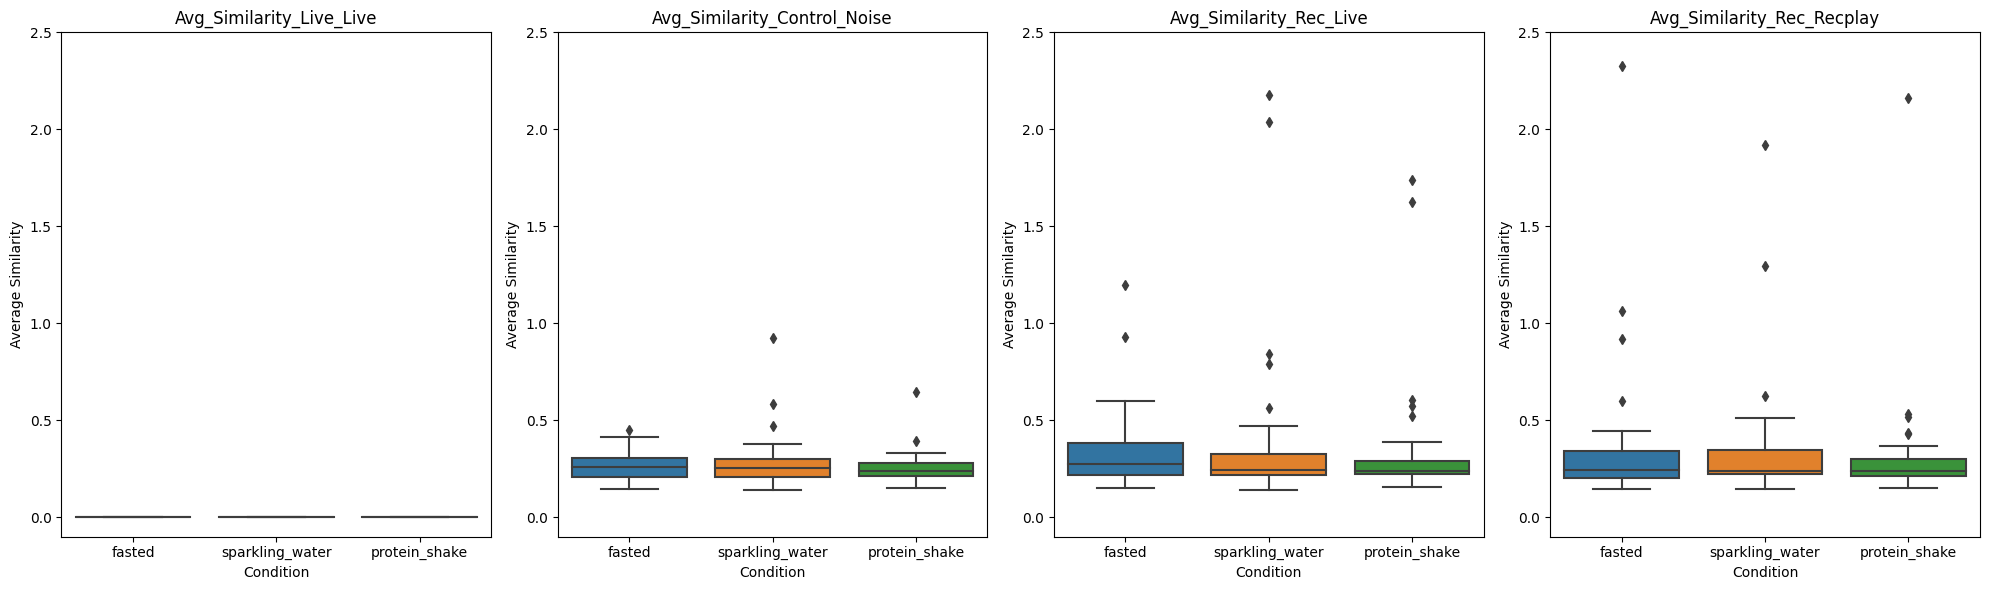

In [65]:
# Create a list of the similarity columns and their corresponding colors
similarity_columns = [
    'Avg_Similarity_Live_Live',
    #'Avg_Similarity_Control_Zeros',
    'Avg_Similarity_Control_Noise',
    'Avg_Similarity_Rec_Live',
    'Avg_Similarity_Rec_Recplay'
]

# Define a color map matching your scatter plot colors
colors = {
    'Avg_Similarity_Live_Live': '#6ED379',  # Time_Live_Live
    #'Avg_Similarity_Control_Zeros': '#AED3B2',  # Time_Live_Control_Zeros
    'Avg_Similarity_Control_Noise': '#AED3B2',  # Time_Live_Control_Noise
    'Avg_Similarity_Rec_Live': '#E5587F',  # Time_Rec_Live
    'Avg_Similarity_Rec_Recplay': '#CCCCCC'  # Time_Rec_Recplay
}

# Set up the subplots (one per similarity column)
fig, axes = plt.subplots(nrows=1, ncols=len(similarity_columns), figsize=(20, 6))

# Get global min and max for consistent y-axis scaling across all boxplots
y_min = similarity_df[similarity_columns].min().min()  # Minimum value across all columns
y_max = similarity_df[similarity_columns].max().max()  # Maximum value across all columns

# Loop through each similarity column and create a boxplot for each condition
for idx, col in enumerate(similarity_columns):
    ax = axes[idx]  # Select the appropriate axis for the current subplot
    sns.boxplot(x='Condition', y=col, data=similarity_df, ax=ax)#, palette=[colors[col]])
    
    # Set titles, labels, and consistent y-axis range
    ax.set_title(f'{col}')
    ax.set_xlabel('Condition')
    ax.set_ylabel('Average Similarity')
    #ax.set_ylim(y_min - 0.1, y_max + 0.1)  # Ensure consistent y-axis scaling across all subplots
    ax.set_ylim(-0.1,2.5)

# Adjust the layout for better readability
plt.tight_layout()

# Display the plots
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def calc_euclidean(actual, predic):
    return np.sqrt(np.sum((actual - predic) ** 2))


def calc_cid(Q, C):
    CE_Q = np.sqrt(np.sum(np.diff(Q) ** 2))
    CE_C = np.sqrt(np.sum(np.diff(C) ** 2))
    
    d = np.sqrt(np.sum((Q - C) ** 2)) * (max(CE_Q, CE_C) / min(CE_Q, CE_C))
    return d


# Iterate through each row in the DataFrame
for i, row in trial_df.iterrows():
    live_values = row["Live_Values"] 
    rec_values = row["Recording"]
    rec_play_values = row["Rec_Play_Values"]


    # Optionally plot the results
    #plt.figure(figsize=(20, 4))
    #plt.plot(rec_play_values, label="Not Played Signal", alpha=0.7, linestyle='dashed', color = '#CCCCCC')
    #plt.plot(rec_values, label="Recorded Signal", alpha=0.7, linestyle='dashed', color = '#E5587F')
    #plt.plot(live_values, label="Live Signal", alpha=0.7, color = '#6ED379' )
    #plt.title(f"Trial {i + 1}: Live vs Recorded")
    #plt.xlabel("Sample Index")
    #plt.ylabel("Amplitude")
    #plt.legend()
    #plt.grid(True)
    #plt.show()
    
    # Check if the values are lists or arrays, and handle cases where they are floats
    if isinstance(live_values, (list, np.ndarray)) and isinstance(rec_values, (list, np.ndarray)) and isinstance(rec_play_values, (list, np.ndarray)):
        # Find the shortest length
        min_length = min(len(live_values), len(rec_values), len(rec_play_values))

        # Trim the arrays to the shortest length
        live_values = live_values[:min_length]
        rec_values = rec_values[:min_length]
        rec_play_values = rec_play_values[:min_length]
        time_indices = np.arange(min_length)  # Create an array of time indices

        # Calculate similarity between Live and Recording for each trial (Pearson correlation)
        if len(live_values) > 1 and len(rec_values) > 1:
            sim_rec_live = pearsonr(live_values, rec_values)[0]
        else:
            sim_rec_live = np.nan
        
        # Calculate similarity between Rec_Play and Recording for each trial (Pearson correlation)
        if len(rec_play_values) > 1 and len(rec_values) > 1:
            sim_rec_recplay = pearsonr(rec_play_values, rec_values)[0]
        else:
            sim_rec_recplay = np.nan

        # Calculate correlation along the time dimension
        
        
        if len(live_values) > 1:
            actual = np.array(live_values)
            predic = np.array(rec_values)
            sim_time_rec_live = calc_cid(actual, predic)
        else:
            sim_time_rec_live = np.nan

        if len(rec_play_values) > 1:
            actual = np.array(live_values)
            predic = np.array(rec_play_values)
            sim_time_rec_recplay = calc_cid(actual, predic)
        else:
            sim_time_rec_recplay = np.nan

        if len(live_values) > 1:
            actual = np.array(live_values)
            predic = np.array(live_values)
            sim_time_live_live = calc_cid(actual, predic)
        else:
            sim_time_live_live = np.nan


        if len(live_values) > 1:
            actual = np.array(live_values)
            control_zeros = np.zeros(len(live_values))  # Control vector of zeros
            sim_time_live_control_zeros = calc_cid(actual, control_zeros)  # Compare actual vs control

            # Generate noise based on the distribution of live_values (same length)
            mean = np.mean(live_values)  # Calculate the mean of live_values
            std = np.std(live_values)    # Calculate the standard deviation of live_values
            # Generate control_noise with a normal distribution based on live_values
            control_noise = np.random.normal(loc=mean, scale=std, size=len(live_values))
            sim_time_live_control_noise = calc_cid(actual, control_noise)  # Compare actual vs control
        else:
            sim_time_live_control = np.nan  # Assign NaN when live_values is too short
            sim_time_live_control_noise = np.nan
    else:
        # If values are floats or not valid lists/arrays, skip the similarity calculation
        sim_rec_live = np.nan
        sim_rec_recplay = np.nan
        sim_time_rec_live = np.nan
        sim_time_rec_recplay = np.nan

    # Update the row with calculated similarities
    trial_df.loc[i, "Similarity_Rec_Live"] = sim_rec_live
    trial_df.loc[i, "Similarity_Rec_Recplay"] = sim_rec_recplay
    trial_df.loc[i, "SimilarityTime_Rec_Live"] = sim_time_rec_live
    trial_df.loc[i, "SimilarityTime_Rec_Recplay"] = sim_time_rec_recplay

    trial_df.loc[i, "SimilarityTime_Live_Live"] = sim_time_live_live
    trial_df.loc[i, "SimilarityTime_Live_Control_Zeros"] = sim_time_live_control_zeros
    trial_df.loc[i, "SimilarityTime_Live_Control_Noise"] = sim_time_live_control_noise

    
trial_df = trial_df.drop(trial_df.index[-1]) #remove the last row = (index 31 - only recording not real trial)

# Add the trial data of the current participant to the group data
#group_trial_data.extend(trial_df.to_dict(orient="records"))

# Create a DataFrame with the relevant columns for easier plotting
plot_df = trial_df[['SimilarityTime_Live_Live', 'SimilarityTime_Live_Control_Zeros', 'SimilarityTime_Live_Control_Noise', 'SimilarityTime_Rec_Live', 'SimilarityTime_Rec_Recplay']]

# Set the size of the figure
plt.figure(figsize=(12, 6))

# Create the boxplot
sns.boxplot(data=plot_df, orient="h", linewidth=1.5, color='black', width=0.5, fill=None)

# Generate jitter values
y_jitter = np.random.uniform(-0.1, 0.1, size=len(trial_df))  # Small jitter for spacing

# Overlay scatter plots with corrected jitter application
plt.scatter(trial_df['SimilarityTime_Live_Live'], 0 + y_jitter, 
            color='#6ED379', alpha=0.7, label='Trial Points (Time_Live_Live)', zorder=3)

plt.scatter(trial_df['SimilarityTime_Live_Control_Zeros'], 1 + y_jitter, 
            color='#AED3B2', alpha=0.7, label='Trial Points (Time_Live_Control)', zorder=3)


plt.scatter(trial_df['SimilarityTime_Live_Control_Noise'], 2 + y_jitter, 
            color='#AED3B2', alpha=0.7, label='Trial Points (Time_Live_Control)', zorder=3)


plt.scatter(trial_df['SimilarityTime_Rec_Live'], 3 + y_jitter, 
            color='#E5587F', alpha=0.7, label='Trial Points (Time_Rec_Live)', zorder=3)

plt.scatter(trial_df['SimilarityTime_Rec_Recplay'], 4 + y_jitter, 
            color='#CCCCCC', alpha=0.7, label='Trial Points (Time_Rec_Recplay)', zorder=3)

# Labels and title
plt.xlabel('Similarity', fontsize=12)
plt.yticks([0, 1, 2, 3, 4], ['SimilarityTime_Live_Live', 'SimilarityTime_Live_Control_Zeros','SimilarityTime_Live_Control_Noise', 'SimilarityTime_Rec_Live', 'SimilarityTime_Rec_Recplay'], fontsize=12)
plt.title('Similarity Comparison: Live vs Recorded (Including Time Dimension)', fontsize=14)

# Add a legend
plt.legend()

# Grid and formatting
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

# Adjust plot margins and show the plot
plt.tight_layout()
plt.show()


plt.figure(figsize=(20, 4))
plt.plot(trial_df['SimilarityTime_Rec_Live'], label="SimilarityTime_Rec_Live", alpha=0.7, linestyle='dashed', color = '#CCCCCC')
plt.plot(trial_df['SimilarityTime_Rec_Recplay'], label="SimilarityTime_Rec_Recplay", alpha=0.7, linestyle='dashed', color = '#E5587F')
plt.title(f"Live vs Recorded")
plt.xlabel("Trial")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()




##ANOVA to compare the mean similarity 
import scipy.stats as stats
import pandas as pd
from itertools import combinations

# Define groups
group1 = trial_df['SimilarityTime_Live_Live'].dropna()  
group2 = trial_df['SimilarityTime_Live_Control_Zeros'].dropna()
group3 = trial_df['SimilarityTime_Live_Control_Noise'].dropna()
group4 = trial_df['SimilarityTime_Rec_Live'].dropna()
group5 = trial_df['SimilarityTime_Rec_Recplay'].dropna()

# Perform One-Way ANOVA
f_stat, p_value = stats.f_oneway(group1, group2, group3, group4, group5)

# Print ANOVA results
print(f"\nANOVA F-statistic: {f_stat:.4f}")
print(f"ANOVA p-value: {p_value:.4f}")

# Prepare DataFrame for results
results = []

if p_value < 0.05:
    print("\nThere is a significant difference between at least one pair of groups.")
    # List of groups and names
    groups = [group1, group2, group3, group4, group5]
    group_names = ['Live_Live', 'Live_Control_Zeros', 'Live_Control_Noise', 'Rec_Live', 'Rec_Recplay']
    
    # Store all pairwise combinations in a list
    pairwise_combinations = list(combinations(range(len(groups)), 2))
    num_tests = len(pairwise_combinations)  # Total number of pairwise tests (should be 10 for 5 groups)

    # Perform t-tests and store results
    for (i, j) in pairwise_combinations:
        group1_data = groups[i]
        group2_data = groups[j]
        
        t_stat, t_p_value = stats.ttest_ind(group1_data, group2_data)
        
        # Apply Bonferroni correction
        adjusted_p_value = min(t_p_value * num_tests, 1.0)  # Ensure p-value doesn't exceed 1

        # Append results to list
        results.append({
            "Comparison": f"{group_names[i]} vs {group_names[j]}",
            "T-statistic": f"{t_stat:.4f}",
            "Unadjusted p-value": f"{t_p_value:.4f}",
            "Adjusted p-value (Bonferroni)": f"{adjusted_p_value:.4f}",
            "Significant?": "Yes" if adjusted_p_value < 0.05 else "No"
        })

    # Convert results to a DataFrame and display
    results_df = pd.DataFrame(results)

    print("\nPairwise T-Test Results:\n")
    print(results_df.to_string(index=False))  # Display table in a clean format
   
else:
    print("\nNo significant difference found in ANOVA. Performing pairwise t-tests...\n")


In [ ]:
display(HTML(group_df.to_html()))


In [ ]:
# Step 1: Read the CSV file into a DataFrame
task = 'GASTRIC'
folder_path = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_21_02/physio/'  # Update with your folder path
save_dir = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_21_02/physio/extracted/'
spike_file = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_21_02/physio/sub-007_gastric.smrx'
participant_id = '011'

cleaned_file_name = save_dir + 'sub-' + participant_id + '_GASTRIC_stethoscope_cleaned_channel_data.tsv'

#file_path = os.path.join(root, cleaned_file_name)
#            print(cleaned_file_name)


trimmed_df = pd.read_csv(cleaned_file_name, sep="\t")


trimmed_df['stethoscope_amplitude_clean'] = trimmed_df['stethoscope_amplitude_clean']
# Task markers (these come from the 'markers' column)
task_markers = {
    'LIVE START': 'live_start_end',
    'LIVE END': 'live_start_end',
    'REC START': 'rec_start_end',
    'REC END': 'rec_start_end',
    'START TASK': 'task_start',
    'END TASK': 'task_end',
    'QUESTION': 'question',
}

# Map markers in 'markers' column to task categories
trimmed_df['category'] = trimmed_df['markers'].map(task_markers).fillna('other')

# Filter out 'other' categories (for tasks)
filtered_df = trimmed_df[trimmed_df['category'] != 'other']

# Initialize an empty DataFrame to store trial data
trial_df = pd.DataFrame(columns=["Trial", "Recording", "Live_Values", "Rec_Play_Values", "Similarity_Rec_Live", "Similarity_Rec_Recplay"])



# Step 2: Extract RECORDING_0 first
recording_0_idx = trimmed_df[trimmed_df['markers'] == 'RECORDING_0'].index[0]

# Extract the segment from RECORDING_0 + 15000 (first 15 seconds is training) to RECORDING_0 + 30000
rec_0_start = recording_0_idx + 14999
rec_0_end = recording_0_idx + 29999
rec_0_segment = trimmed_df.loc[rec_0_start:rec_0_end, 'stethoscope_amplitude_clean'].values

i = 0
# Add RECORDING_0 to trial_df
trial_df.loc[i, "Trial"] = i
trial_df.loc[i, "Recording"] = rec_0_segment.tolist()
#trial_df.loc[i, "Live_Values"] = np.nan  # Will be filled later with corresponding trial live values
#trial_df.loc[i, "Rec_Play_Values"] = np.nan  # Will be filled later with corresponding trial rec play values
#trial_df.loc[i, "Similarity_Rec_Live"] = np.nan  # Similarity will be calculated later
#trial_df.loc[i, "Similarity_Rec_Recplay"] = np.nan  # Similarity will be calculated later

#display(HTML(trial_df.head().to_html()))


# Step 3: Filter DataFrame from TRIAL_0-COND_Fasted onward
trial_start_idx = trimmed_df[trimmed_df['markers'] == 'TRIAL_0-COND_Fasted'].index[0]
filtered_df = trimmed_df.loc[trial_start_idx:]

# Step 4: Find indices for LIVE START, LIVE END, REC START, and REC END
live_start_indices = filtered_df[filtered_df['markers'] == 'LIVE START'].index
live_end_indices = filtered_df[filtered_df['markers'] == 'LIVE END'].index
rec_play_start_indices = filtered_df[filtered_df['markers'] == 'REC START'].index
rec_play_end_indices = filtered_df[filtered_df['markers'] == 'REC END'].index
recording_indices = filtered_df[filtered_df['markers'].notna() & filtered_df['markers'].str.startswith('RECORDING_')].index


# Step 5: Loop through each trial and extract LIVE and REC_PLAY segments
for i in range(len(live_start_indices)):  # Loop through all trials
    
    live_start = live_start_indices[i]
    live_end = live_end_indices[i]
    rec_play_start = rec_play_start_indices[i]
    rec_play_end = rec_play_end_indices[i]
    recording_idx_start = recording_indices[i] 
    
    #if verbose: 
    #    print('Trial: ', i)
        
    # Extract the recording segment (RECORDING_X)
    rec_segment_start = recording_idx_start
    rec_segment_end = rec_segment_start + 14999
    rec_segment = trimmed_df.loc[rec_segment_start:rec_segment_end, 'stethoscope_amplitude_clean'].values
    
    # Extract the live segment for the trial (LIVE START to LIVE END)
    live_segment = filtered_df.loc[live_start:live_end, 'stethoscope_amplitude_clean'].values
    
    # Extract the REC_PLAY segment for the trial (REC START to REC END)
    rec_play_segment = filtered_df.loc[rec_play_start:rec_play_end, 'stethoscope_amplitude_clean'].values
    
    # Assign live and rec_play values manually
    trial_df.loc[i, "Trial"] = i
    trial_df.loc[i, "Live_Values"] = live_segment.tolist()
    trial_df.loc[i, "Rec_Play_Values"] = rec_play_segment.tolist()
    trial_df.loc[i + 1, "Recording"] = rec_segment.tolist()
    trial_df.loc[i, "Similarity_Rec_Live"] = np.nan  # Similarity will be calculated later
    trial_df.loc[i, "Similarity_Rec_Recplay"] = np.nan  # Similarity will be calculated later
 
    
    # Optionally plot the results
    plt.figure(figsize=(20, 4))
    plt.plot(rec_play_segment, label="Not Played Signal", alpha=0.5, color = '#CCCCCC')
    plt.plot(trial_df.loc[i, "Recording"], label="Recorded Signal", alpha=0.5, color = '#E5587F')
    plt.plot(trial_df.loc[i, "Live_Values"], label="Live Signal", alpha=0.5, color = '#6ED379' )
    plt.title(f"Trial {i}: Live vs Recorded")
    plt.xlabel("Sample Index")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()

    #if verbose: 
    #    if i == 29:
    #        display(HTML(trial_df.head().to_html()))


### Euclidian distance illustration

Euclidean Distance: 15.590499150914072


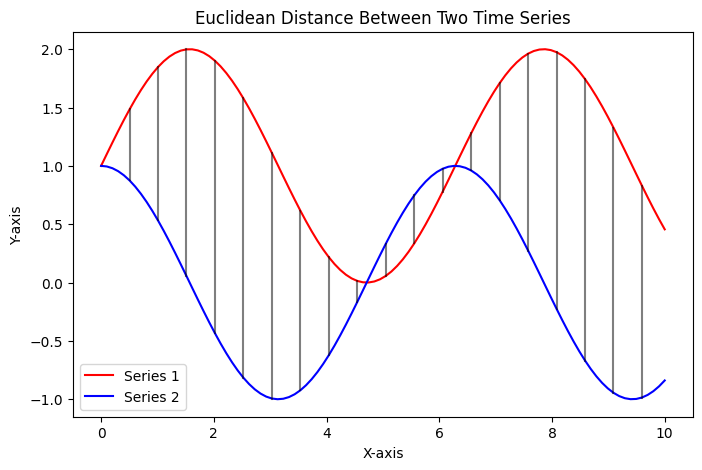

In [33]:
import numpy as np
import matplotlib.pyplot as plt

def calc_euclidean(actual, predic):
    return np.sqrt(np.sum((actual - predic) ** 2))

# Example usage
if __name__ == "__main__":
    x = np.linspace(0, 10, 100)
    series1 = np.sin(x) + 1  # Shifted sine wave (red)
    series2 = np.cos(x)  # Cosine wave (blue)
    
    # Compute Euclidean distance
    distance = calc_euclidean(series1, series2)
    print(f"Euclidean Distance: {distance}")
    
    # Plot the two series
    plt.figure(figsize=(8, 5))
    plt.plot(x, series1, 'r-', label='Series 1')
    plt.plot(x, series2, 'b-', label='Series 2')
    
    # Add vertical lines to indicate distances
    for i in range(0, len(x), 5):  # Reduce number of lines for clarity
        plt.plot([x[i], x[i]], [series1[i], series2[i]], 'k-', alpha=0.5)
    
    plt.xlabel("X-axis")
    plt.ylabel("Y-axis")
    plt.legend()
    plt.title("Euclidean Distance Between Two Time Series")
    plt.show()

Euclidean Distance: 0.4637068199522911
CID Distance: 0.6543916525933525


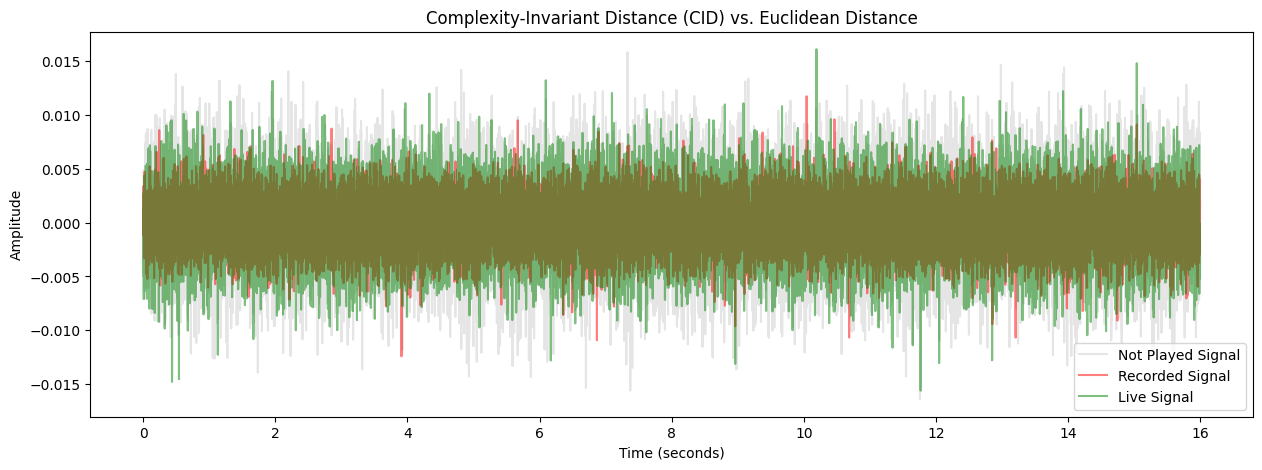

In [52]:
import numpy as np
import matplotlib.pyplot as plt

def calc_euclidean(actual, predic):
    return np.sqrt(np.sum((actual - predic) ** 2))

def calc_complexity(series):
    return np.sqrt(np.sum(np.diff(series) ** 2))

def CID(Q, C):
    CE_Q = calc_complexity(Q)
    CE_C = calc_complexity(C)
    
    if CE_Q == 0 or CE_C == 0:
        return calc_euclidean(Q, C)  # Avoid division by zero
    
    complexity_ratio = max(CE_Q, CE_C) / min(CE_Q, CE_C)
    return calc_euclidean(Q, C) * complexity_ratio

# Generate noisy time series (similar to your image)
samples = 16000  # Smaller subset for visualization
fs = 1000  # Sampling frequency (Hz)
time = np.arange(samples) / fs  # Convert sample index to time in seconds

np.random.seed(42)

series1 = np.random.normal(0, 0.001, samples)  # Low noise baseline (gray)
series2 = series1 + np.random.normal(0, 0.002, samples)  # More variation (pink)
series3 = series1 + np.random.normal(0, 0.003, samples)  # Even more variation (green)
series1 = series1 + np.random.normal(0, 0.004, samples)  # Low noise baseline (gray)

# Add sporadic spikes to simulate real-world behavior
spike_indices = np.random.choice(samples, size=50, replace=False)
series2[spike_indices] += np.random.uniform(-0.01, 0.01, size=50)
series3[spike_indices] += np.random.uniform(-0.015, 0.015, size=50)

# Compute distances
euclidean_distance = calc_euclidean(series2, series3)
cid_distance = CID(series2, series3)

print(f"Euclidean Distance: {euclidean_distance}")
print(f"CID Distance: {cid_distance}")

# Plot the signals
plt.figure(figsize=(15, 5))
plt.plot(time, series1, color='gray', alpha=0.2, label="Not Played Signal")
plt.plot(time, series2, color='red', alpha=0.5, label="Recorded Signal")
plt.plot(time, series3, color='green', alpha=0.5, label="Live Signal")

plt.xlabel("Time (seconds)")  # Changed x-axis label
plt.ylabel("Amplitude")
plt.legend()
plt.title("Complexity-Invariant Distance (CID) vs. Euclidean Distance")

plt.show()


Normative range of CID values relative to the mean 

In [3]:
def process_normative_CID(trimmed_df, participant_id, plots = False):
    # Initialize an empty list to collect results for all trials
    result_data = []

    trimmed_df['stethoscope_amplitude_clean'] = trimmed_df['stethoscope_amplitude_clean']
    # Task markers (these come from the 'markers' column)
    task_markers = {
        'LIVE START': 'live_start_end',
        'LIVE END': 'live_start_end',
        'REC START': 'rec_start_end',
        'REC END': 'rec_start_end',
        'START TASK': 'task_start',
        'END TASK': 'task_end',
        'QUESTION': 'question',
    }
    
    # Map markers in 'markers' column to task categories
    trimmed_df['category'] = trimmed_df['markers'].map(task_markers).fillna('other')
    
    # Filter out 'other' categories (for tasks)
    filtered_df = trimmed_df[trimmed_df['category'] != 'other']
    
    # Initialize an empty DataFrame to store trial data
    trial_df = pd.DataFrame(columns=["Trial", "Recording", "Live_Values", "Rec_Play_Values", "Similarity_Rec_Live", "Similarity_Rec_Recplay"])
      
    # Step 2: Extract RECORDING_0 first
    recording_0_idx = trimmed_df[trimmed_df['markers'] == 'RECORDING_0'].index[0]
    
    # Extract the segment from RECORDING_0 + 15000 (first 15 seconds is training) to RECORDING_0 + 30000
    rec_0_start = recording_0_idx + 14999
    rec_0_end = recording_0_idx + 29999
    rec_0_segment = trimmed_df.loc[rec_0_start:rec_0_end, 'stethoscope_amplitude_clean'].values
    
    i = 0
    # Add RECORDING_0 to trial_df
    trial_df.loc[i, "Trial"] = i
    trial_df.loc[i, "Recording"] = rec_0_segment.tolist()
       
    # Step 3: Filter DataFrame from TRIAL_0-COND_Fasted onward
    trial_start_idx = trimmed_df[trimmed_df['markers'] == 'TRIAL_0-COND_Fasted'].index[0]
    filtered_df = trimmed_df.loc[trial_start_idx:]
    
    # Step 4: Find indices for LIVE START, LIVE END, REC START, and REC END
    live_start_indices = filtered_df[filtered_df['markers'] == 'LIVE START'].index
    live_end_indices = filtered_df[filtered_df['markers'] == 'LIVE END'].index
    rec_play_start_indices = filtered_df[filtered_df['markers'] == 'REC START'].index
    rec_play_end_indices = filtered_df[filtered_df['markers'] == 'REC END'].index
    recording_indices = filtered_df[filtered_df['markers'].notna() & filtered_df['markers'].str.startswith('RECORDING_')].index
    
    
    # Step 5: Loop through each trial and extract LIVE and REC_PLAY segments
    for i in range(len(live_start_indices)):  # Loop through all trials
        
        live_start = live_start_indices[i]
        live_end = live_end_indices[i]
        rec_play_start = rec_play_start_indices[i]
        rec_play_end = rec_play_end_indices[i]
        recording_idx_start = recording_indices[i] 
  
        # Extract the recording segment (RECORDING_X)
        rec_segment_start = recording_idx_start
        rec_segment_end = rec_segment_start + 14999
        rec_segment = trimmed_df.loc[rec_segment_start:rec_segment_end, 'stethoscope_amplitude_clean'].values
        
        # Extract the live segment for the trial (LIVE START to LIVE END)
        live_segment = filtered_df.loc[live_start:live_end, 'stethoscope_amplitude_clean'].values
        
        # Extract the REC_PLAY segment for the trial (REC START to REC END)
        rec_play_segment = filtered_df.loc[rec_play_start:rec_play_end, 'stethoscope_amplitude_clean'].values
        
        # Assign live and rec_play values manually
        trial_df.loc[i, "Trial"] = i
        trial_df.loc[i, "Live_Values"] = live_segment.tolist()
        trial_df.loc[i, "Rec_Play_Values"] = rec_play_segment.tolist()
        trial_df.loc[i + 1, "Recording"] = rec_segment.tolist()
        

    trial_df = trial_df.drop(trial_df.index[-1]) #remove the last row = (index 31 - only recording not real trial)
    
    # Convert the result data to a DataFrame
    return trial_df

In [4]:
import glob
task = 'GASTRIC'
folder_path = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio/'  # Edit folder path
save_dir = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_01_04/physio/'

# Main processing loop for participants
group_df = pd.DataFrame(columns=["Participant_ID", "Trial", 
                                 "Live_Values", "Rec_Play_Values", 
                                 "Recording"])
file_names = []
cleaned_file_already_saved = True

file_pattern = os.path.join(folder_path, "*_stethoscope_cleaned_channel_data.tsv")
file_paths = glob.glob(file_pattern)

for file_path in file_paths:
    # Get the filename from the full file path
    file_name = os.path.basename(file_path)
    #print(f"File path: {file_path}")
    #print(f"File name: {file_name}")
    
    # Extract the participant ID from the filename (assuming the format "sub-XXX_gastric_stethascope_cleaned_channel_data.tsv")
    participant_id = file_name.split('_')[0]  # Get the part before the first underscore (sub-XXX)
    print(f"Participant ID: {participant_id}")
    file_path = save_dir + f"{participant_id}_" + task + '_stethoscope_cleaned_channel_data.tsv'
    clean_trimmed_df = pd.read_csv(file_path, sep = '\t') 

    participant_group_df = process_normative_CID(clean_trimmed_df, participant_id, plots = True)
    # Concatenate the results for the participant to the group_df
    group_df = pd.concat([group_df, participant_group_df], ignore_index=True)


Participant ID: sub-004


C:\Users\hsavage\AppData\Local\Temp\ipykernel_29124\3189853215.py:26: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


Participant ID: sub-006


C:\Users\hsavage\AppData\Local\Temp\ipykernel_29124\3189853215.py:26: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


Participant ID: sub-007


C:\Users\hsavage\AppData\Local\Temp\ipykernel_29124\3189853215.py:26: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


... (78 outputs left out)

Participant ID: sub-141


C:\Users\hsavage\AppData\Local\Temp\ipykernel_29124\3189853215.py:26: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


Participant ID: sub-142


C:\Users\hsavage\AppData\Local\Temp\ipykernel_29124\3189853215.py:26: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  clean_trimmed_df = pd.read_csv(file_path, sep = '\t')


In [5]:
print(group_df)

     Participant_ID Trial                                        Live_Values  \
0               NaN     0  [-0.0005306759405338, 0.0008895004089949, 0.00...   
1               NaN     1  [0.0010266945159194, 0.0007945009481153, 0.000...   
2               NaN     2  [0.0024918877800081, 0.0007234374171669, -0.00...   
3               NaN     3  [0.0002454770965719, 0.0009455245505603, 0.000...   
4               NaN     4  [0.0006060108874052, -0.0001692248722419, 0.00...   
...             ...   ...                                                ...   
1345            NaN    25  [-0.0007200217223126, 0.0007998851638611, 0.00...   
1346            NaN    26  [-0.0016091361891751, 0.000536071796371, -0.00...   
1347            NaN    27  [-0.0004173470511564, 0.0006342270846284, -0.0...   
1348            NaN    28  [-0.0001736016164651, 0.0007647050736646, -0.0...   
1349            NaN    29  [0.0006673627455613, -7.306578968362702e-05, 0...   

                                       

In [6]:
long_list = group_df['Live_Values'].tolist() + group_df['Rec_Play_Values'].tolist() + group_df['Recording'].tolist()

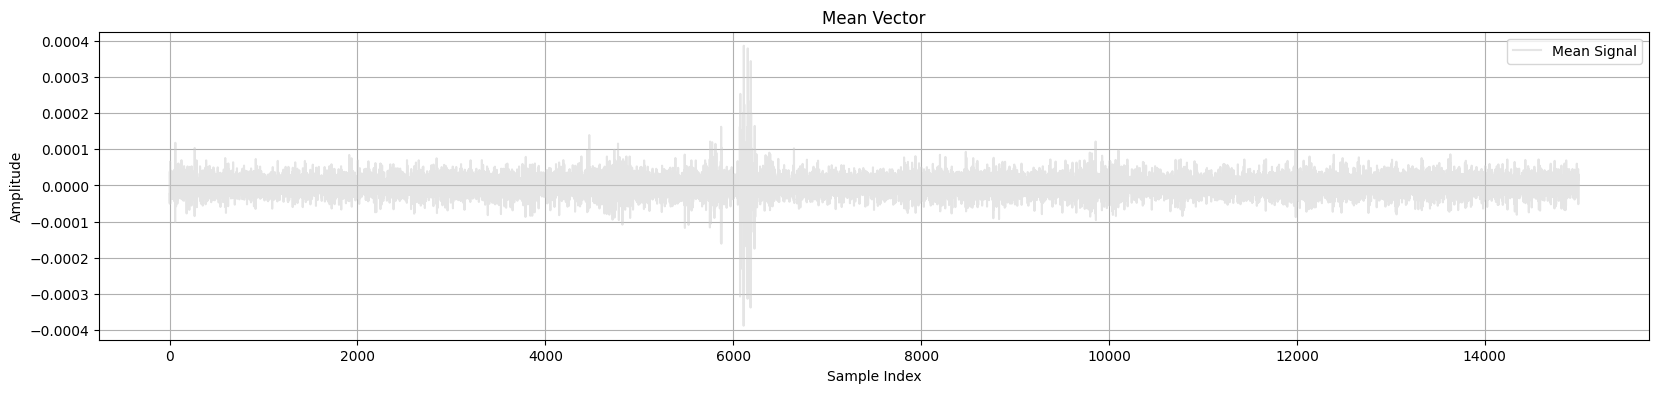

In [9]:
# Remove anything that's not a list/array or is too short
valid_segments = [seg for seg in long_list if isinstance(seg, (list, np.ndarray)) and len(seg) > 1]

# Find the minimum length to standardize on
min_len = min(len(seg) for seg in valid_segments)

# Trim each segment to the same length
trimmed_segments = [np.array(seg[:min_len]) for seg in valid_segments]

# Now stack safely
array = np.stack(trimmed_segments)  # shape (N, min_len)

# Now you can compute the mean vector
mean_vector = np.mean(array, axis=0)

# Plotting
plt.figure(figsize=(20, 4))
plt.plot(mean_vector, label="Mean Signal", alpha=0.5, color='#CCCCCC')
plt.title("Mean Vector")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
#plt.ylim(-0.02, 0.02)
plt.show()

In [10]:
def calc_cid(Q, C):
    CE_Q = np.sqrt(np.sum(np.diff(Q) ** 2))
    CE_C = np.sqrt(np.sum(np.diff(C) ** 2))
    d = np.sqrt(np.sum((Q - C) ** 2)) * (max(CE_Q, CE_C) / min(CE_Q, CE_C))
    return d

# STEP 1: Get all segments from the DataFrame into one long list
all_segments = group_df['Live_Values'].tolist() + \
               group_df['Rec_Play_Values'].tolist() + \
               group_df['Recording'].tolist()

# STEP 2: Convert to numpy arrays and filter out any non-array-like or NaNs
all_segments = [np.array(seg) for seg in all_segments if isinstance(seg, (list, np.ndarray)) and len(seg) > 1]

# STEP 3: Pad/truncate all arrays to same length (necessary for mean vector and CID comparison)
min_length = min(len(seg) for seg in all_segments)
all_segments = [seg[:min_length] for seg in all_segments]

# STEP 4: Stack and compute mean vector
stacked = np.stack(all_segments)  # shape: (n_samples, min_length)
mean_vector = np.mean(stacked, axis=0)

# STEP 5: Define function to apply CID to a cell vs. mean_vector
def calculate_cid_against_mean(segment):
    if isinstance(segment, (list, np.ndarray)) and len(segment) >= min_length:
        segment = np.array(segment[:min_length])
        return calc_cid(segment, mean_vector)
    return np.nan

# STEP 6: Apply to all three columns and store in new columns
group_df['CID_Live_vs_Mean'] = group_df['Live_Values'].apply(calculate_cid_against_mean)
group_df['CID_RecPlay_vs_Mean'] = group_df['Rec_Play_Values'].apply(calculate_cid_against_mean)
group_df['CID_Recording_vs_Mean'] = group_df['Recording'].apply(calculate_cid_against_mean)